# Subgrupos moleculares en cáncer de estómago (TCGA-STAD)
## Análisis de expresión génica con aprendizaje no supervisado: PCA, K-means y clustering jerárquico

**Autor:** _Bruno Morales Rosales_  
**Datos:** GDC TCGA Stomach Cancer (STAD), vía UCSC Xena

---

### Resumen

Se analizó la expresión génica (RNA-seq) de **412 tumores primarios de estómago** del proyecto TCGA para buscar, sin usar ninguna etiqueta, grupos de tumores con perfiles parecidos, y después se comparó esos grupos con las variables clínicas.

- **La estructura es un continuo, no islas separadas.** Los 10 primeros componentes principales explican el 48.9 % de la varianza y los grupos se solapan (silueta media 0.16). Los ejes dominantes son biológicos: cantidad de estroma frente a epitelio proliferativo (PC1), infiltración inmune (PC2) y diferenciación epitelial (PC3).
- **K-means con k = 4** dio la partición más útil: es estable al submuestrear (ARI medio 0.86) y cada grupo tiene un perfil reconocible: **C1** epitelial de tipo intestinal, **C2** proliferativo e inmune-frío con antígenos cáncer-testículo, **C3** inmune-inflamado y **C4** estromal/mesenquimal.
- **El clustering jerárquico (Ward) encuentra los mismos ejes pero corta en otros lugares** (ARI = 0.29 frente a K-means; 63 % de los tumores en el grupo equivalente). La discrepancia se concentra en los tumores de frontera.
- **Los grupos se asocian con la clínica:** histología de Lauren (p = 1 × 10⁻¹¹; C4 concentra los tumores difusos), profundidad de invasión T, estadio, edad (C4 es 6 años más joven) y región del estómago. No se asocian con sexo, ganglios ni metástasis.
- **La supervivencia no difiere de forma significativa** (log-rank p = 0.14), aunque el orden observado (C4 peor, C1 mejor) coincide con lo publicado.
- **Advertencia principal:** el centro que aportó la muestra también se asocia con los clusters (p = 2 × 10⁻⁹), así que parte de la señal puede ser técnica o de composición de la cohorte.

### Contenido

1. Planteamiento del problema y contexto de los datos
2. Configuración y carga de datos
3. Exploración y comprensión del conjunto de datos
4. Preparación y tratamiento de los datos
5. Reducción de dimensionalidad mediante PCA
6. Construcción y comparación de modelos de clustering
7. Interpretación de los clusters: análisis de genes
8. Interpretación de los clusters: análisis clínico
9. Discusión frente a la literatura
10. Conclusión y reflexión final

## 1. Planteamiento del problema y contexto de los datos

### 1.1 El cáncer de estómago

El cáncer gástrico es el quinto cáncer más diagnosticado y la quinta causa de muerte por cáncer en el mundo: en 2022 se estimaron cerca de 968 000 casos nuevos y 660 000 muertes [4]. Más del 90 % de los casos son **adenocarcinomas**, es decir, tumores que nacen del epitelio glandular que recubre el estómago; de ahí el nombre del proyecto, *Stomach Adenocarcinoma* (STAD).

Es una enfermedad muy heterogénea. La clasificación histológica clásica, la de Lauren [5], distingue dos grandes formas:

- **Tipo intestinal:** las células forman glándulas, suele aparecer en personas mayores y se relaciona con la infección crónica por *Helicobacter pylori*.
- **Tipo difuso:** las células pierden la adhesión entre sí e infiltran la pared del estómago de forma dispersa (incluye el carcinoma de células en anillo de sello); tiende a presentarse a menor edad y tiene peor pronóstico.

Esta clasificación se basa en lo que se ve al microscopio y predice mal la respuesta al tratamiento. Dos tumores con la misma histología y el mismo estadio pueden comportarse de forma muy distinta.

### 1.2 Por qué estudiar la estructura de los datos de expresión

La expresión génica mide qué genes están activos en el tumor y en qué cantidad. Si existen subgrupos de tumores con programas de expresión distintos, podrían corresponder a biologías distintas (más proliferación, más respuesta inmune, más tejido de soporte…) y, eventualmente, a pronósticos o tratamientos diferentes. Esa fue la lógica de las clasificaciones moleculares publicadas por TCGA en 2014 [1] y por el Asian Cancer Research Group (ACRG) en 2015 [2].

El aprendizaje **no supervisado** es la herramienta natural para esta pregunta: no se le dice al algoritmo qué grupos buscar, sino que se le pide que describa la estructura que haya en los datos.

### 1.3 Objetivo y preguntas

**Objetivo general:** identificar patrones y agrupaciones en la expresión génica de los tumores gástricos de TCGA y explorar su relación con las variables clínicas.

Preguntas concretas:

1. ¿Cuántas dimensiones hacen falta para describir la variación entre tumores y qué representan?
2. ¿Los tumores forman grupos definidos o un continuo? ¿Cuántos grupos es razonable distinguir?
3. ¿K-means y el clustering jerárquico llegan a la misma respuesta?
4. ¿Qué genes distinguen a los grupos y qué biología sugieren?
5. ¿Los grupos difieren en edad, sexo, histología, estadio o supervivencia?
6. ¿Se parecen a los subtipos descritos en la literatura?

**Qué se espera aprender:** si la expresión por sí sola recupera subgrupos interpretables, qué tan robustos son y cuáles son los límites de este tipo de análisis.

### 1.4 Origen de los datos

Los datos provienen de **The Cancer Genome Atlas (TCGA)**, proyecto TCGA-STAD, en la versión reprocesada por el *Genomic Data Commons* (GDC) y distribuida por **UCSC Xena** [3] (cohorte «GDC TCGA Stomach Cancer (STAD)»). Se usan cuatro archivos:

| Archivo | Contenido | Papel en el análisis |
|---|---|---|
| `TCGA-STAD.star_tpm.tsv.gz` | Expresión de 60 660 genes por muestra. RNA-seq alineado con STAR y cuantificado en TPM (*transcripts per million*), transformado como log2(TPM + 1) | Entrada del PCA y del clustering |
| `TCGA-STAD.clinical.tsv.gz` | 85 variables clínicas y de la muestra: edad, sexo, estadio, histología, centro de origen… | Caracterización de los clusters |
| `TCGA-STAD.survival.tsv.gz` | Supervivencia global: evento (`OS`) y tiempo en días (`OS.time`) | Curvas de supervivencia por cluster |
| `gencode.v36.annotation.gtf.gene.probemap` | Correspondencia entre el identificador Ensembl de cada gen y su símbolo, cromosoma y posición | Nombrar los genes y filtrarlos |

La expresión es la materia prima para descubrir subgrupos; las variables clínicas **no** participan en el agrupamiento y se usan después para preguntarse si los grupos encontrados significan algo para el paciente.

In [42]:
import os, glob, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import pdist
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, adjusted_mutual_info_score)
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 0
pd.set_option("display.max_columns", 50, "display.width", 250, "display.max_colwidth", 250)

# --- Estilo de las figuras (una sola paleta para todo el reporte) ---
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
AZUL, NARANJA, GRIS, ROJO = "#2a78d6", "#eb6834", "#9a9992", "#e34948"
COL_CLUSTER = ["#2a78d6", "#eda100", "#008300", "#e87ba4"]   # validada para daltonismo (4 grupos)
MARCADORES = ["o", "s", "^", "D"]                            # segunda codificación además del color
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#f7fafe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#f0efec", "#e34948", "#8f2323"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b9b8b2",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "font.size": 9.5, "legend.frameon": False, "legend.fontsize": 9,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

# Carpeta donde están los 4 archivos descargados de UCSC Xena.
# En Google Colab: súbelos al panel "Archivos" (quedan en "/content", que es la carpeta actual)
# o monta Drive y cambia esta ruta, p. ej. DATA_DIR = "/content/drive/MyDrive/STAD"
DATA_DIR = "./Datos"

In [4]:
# Versiones con las que se generaron los resultados (para reproducibilidad)
import sys, sklearn, scipy
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", mpl.__version__)

Python 3.14.4 | numpy 2.5.5 | pandas 2.3.3 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [5]:
def buscar(patron):
    """Localiza un archivo por patrón, sin depender del nombre exacto con el que se guardó."""
    hallados = sorted(glob.glob(os.path.join(DATA_DIR, patron)))
    if not hallados:
        raise FileNotFoundError(f"No encontré ningún archivo '{patron}' en DATA_DIR = {DATA_DIR!r}")
    return hallados[0]

F_EXPR = buscar("*star_tpm*")     # expresión génica, log2(TPM+1)
F_CLIN = buscar("*clinical*")     # variables clínicas (fenotipo)
F_SURV = buscar("*survival*")     # supervivencia global
F_MAP  = buscar("*probemap*")     # mapeo Ensembl ID -> símbolo del gen

try:
    expr = pd.read_csv(F_EXPR, sep="\t", index_col=0)          # filas = genes, columnas = muestras
except EOFError as e:
    raise EOFError(
        f"El archivo {F_EXPR} está incompleto o dañado (descarga interrumpida).\n"
        f"Por favor, vuelve a descargarlo de UCSC Xena o súbelo de nuevo por completo (pesa unos 147 MB)."
    ) from e

clin = pd.read_csv(F_CLIN, sep="\t")
surv = pd.read_csv(F_SURV, sep="\t")
gmap = pd.read_csv(F_MAP, sep="\t").set_index("id")

for nombre, f, df in [("Expresión", F_EXPR, expr), ("Clínica", F_CLIN, clin),
                      ("Supervivencia", F_SURV, surv), ("Mapeo de genes", F_MAP, gmap)]:
    print(f"{nombre:<15} {df.shape[0]:>6,} filas x {df.shape[1]:>3} columnas   ({os.path.basename(f)})")

Expresión       60,660 filas x 448 columnas   (TCGA-STAD.star_tpm.tsv)
Clínica            511 filas x  86 columnas   (TCGA-STAD.clinical.tsv)
Supervivencia      469 filas x   4 columnas   (TCGA-STAD.survival.tsv)
Mapeo de genes  60,660 filas x   5 columnas   (gencode.v36.annotation.gtf.gene.probemap)


## 3. Exploración y comprensión del conjunto de datos

### 3.1 Estructura y tamaño

Antes de modelar hay que saber qué hay en las tablas: cuántas muestras, de qué tipo, cuántos genes y qué tan bien se cruzan los cuatro archivos. Cada columna de la matriz de expresión es una muestra identificada con un código de barras TCGA (por ejemplo `TCGA-BR-6457-01A`): los primeros 12 caracteres identifican al paciente y los dígitos 14–15 el tipo de muestra (`01` tumor primario, `11` tejido normal adyacente).

In [6]:
# El código de barras TCGA codifica el tipo de muestra en los caracteres 14-15:
# 01 = tumor primario, 11 = tejido normal adyacente
tipo = pd.Series(expr.columns.str[13:15], index=expr.columns).map(
    {"01": "Tumor primario", "11": "Tejido normal adyacente"})
paciente = pd.Series(expr.columns.str[:12], index=expr.columns)
tumores = tipo.index[tipo == "Tumor primario"].tolist()
normales = tipo.index[tipo == "Tejido normal adyacente"].tolist()

resumen = pd.Series({
    "Genes (filas de la matriz de expresión)": expr.shape[0],
    "Muestras con expresión": expr.shape[1],
    "   · tumores primarios": len(tumores),
    "   · tejido normal adyacente": len(normales),
    "Pacientes distintos": paciente.nunique(),
    "Pacientes con más de un tumor secuenciado": int(paciente[tumores].duplicated().sum()),
    "Muestras en la tabla clínica": clin["sample"].nunique(),
    "Variables clínicas (columnas)": clin.shape[1] - 1,
    "Tumores con expresión y datos clínicos": int(pd.Index(tumores).isin(clin["sample"]).sum()),
    "Tumores con expresión y supervivencia": int(pd.Index(tumores).isin(surv["sample"]).sum()),
}, name="n").to_frame()
display(resumen)

,n
Genes (filas de la matriz de expresión),60660
Muestras con expresión,448
· tumores primarios,412
· tejido normal adyacente,36
Pacientes distintos,415
Pacientes con más de un tumor secuenciado,0
Muestras en la tabla clínica,511
Variables clínicas (columnas),85
Tumores con expresión y datos clínicos,412
Tumores con expresión y supervivencia,385


In [7]:
# Comprobación de la escala: si los valores son log2(TPM+1), al deshacer la transformación
# cada muestra debe sumar un millón.
suma_tpm = (np.power(2.0, expr) - 1).sum(axis=0)
print(f"Rango de valores: {expr.values.min():.2f} a {expr.values.max():.2f}")
print(f"Suma de (2^x - 1) por muestra: mínimo {suma_tpm.min():,.0f}, máximo {suma_tpm.max():,.0f}")
print("Primeras filas de la matriz de expresión:")
display(expr.iloc[:4, :4].round(3))
print("Mapeo de genes:")
display(gmap.head(3))

Rango de valores: 0.00 a 17.73
Suma de (2^x - 1) por muestra: mínimo 1,000,000, máximo 1,000,000
Primeras filas de la matriz de expresión:


,TCGA-BR-6457-01A,TCGA-BR-6457-11A,TCGA-RD-A7BT-01A,TCGA-CD-8530-01A
Ensembl_ID,,,,
ENSG00000000003.15,4.333,3.587,6.179,4.166
ENSG00000000005.6,0.202,0.137,0.084,0.041
ENSG00000000419.13,5.890,4.925,7.857,6.460
ENSG00000000457.14,2.211,1.925,2.680,2.946


Mapeo de genes:


,gene,chrom,chromStart,chromEnd,strand
id,,,,,
ENSG00000223972.5,DDX11L1,chr1,11869,14409,+
ENSG00000227232.5,WASH7P,chr1,14404,29570,-
ENSG00000278267.1,MIR6859-1,chr1,17369,17436,-


**Lectura:**

- La matriz tiene **60 660 genes** (filas) y **448 muestras** (columnas): **412 tumores primarios** y **36 muestras de tejido normal** adyacente, de 415 pacientes. Ningún paciente aporta más de un tumor, así que las observaciones tumorales son independientes.
- Los 412 tumores tienen datos clínicos y 385 tienen registro de supervivencia.
- La escala es la esperada: al deshacer el logaritmo cada muestra suma exactamente un millón, lo que confirma que los valores son **log2(TPM + 1)**. Los genes vienen identificados con códigos Ensembl (`ENSG…`), por eso hace falta el archivo de mapeo para leer los resultados.

Es el escenario típico de la genómica: **muchas más variables que observaciones** (60 660 genes frente a 412 tumores), lo que hace indispensable filtrar y reducir dimensiones antes de agrupar.

### 3.2 Variables clínicas disponibles

La tabla clínica tiene 85 columnas, pero muchas no sirven para el análisis. La siguiente celda las clasifica automáticamente y después se muestra un diccionario de las que sí se usarán. En GDC muchos datos ausentes no aparecen como celdas vacías sino como el texto «Not Reported»; aquí se cuentan como faltantes.

In [8]:
# Tabla clínica restringida a los tumores que tienen expresión
clin_t = clin.set_index("sample").reindex(tumores)

# En GDC muchos faltantes no vienen como NaN sino como texto ("Not Reported", "unknown"...)
TEXTO_FALTANTE = {"not reported", "unknown", "not allowed to collect", ""}
def a_nan(col):
    if col.dtype.kind in "biuf":
        return col
    return col.where(~col.astype(str).str.strip().str.lower().isin(TEXTO_FALTANTE))
clin_t = clin_t.apply(a_nan)

def clasificar(nombre, col):
    if col.isna().mean() > 0.5:
        return "Mayormente vacía (>50 % faltante)"
    if col.nunique(dropna=True) <= 1:
        return "Constante (un solo valor)"
    if re.search(r"(_id|\bid\b|uuid|datetime|submitter|^code\.|state\.|treatment)", nombre):
        return "Identificador / administrativa"
    return "Informativa"
clase = pd.Series({c: clasificar(c, clin_t[c]) for c in clin_t.columns})
display(clase.value_counts().rename("n.º de columnas").to_frame())

,n.º de columnas
Informativa,28
Mayormente vacía (>50 % faltante),26
Constante (un solo valor),17
Identificador / administrativa,14


In [9]:
# Diccionario de las variables clínicas que se usan en el análisis
DICCIONARIO = {
    "age_at_index.demographic": "Edad al diagnóstico (años)",
    "gender.demographic": "Sexo",
    "race.demographic": "Raza reportada",
    "vital_status.demographic": "Estado vital al último seguimiento",
    "ajcc_pathologic_stage.diagnoses": "Estadio patológico AJCC (I–IV, con subestadios)",
    "ajcc_pathologic_t.diagnoses": "T: profundidad de invasión del tumor primario",
    "ajcc_pathologic_n.diagnoses": "N: ganglios linfáticos regionales afectados",
    "ajcc_pathologic_m.diagnoses": "M: metástasis a distancia",
    "primary_diagnosis.diagnoses": "Diagnóstico histológico (incluye tipo de Lauren)",
    "tissue_or_organ_of_origin.diagnoses": "Región anatómica del estómago",
    "prior_malignancy.diagnoses": "Antecedente de otra neoplasia",
    "ajcc_staging_system_edition.diagnoses": "Edición del manual AJCC usada para estadificar",
    "name.tissue_source_site": "Centro que aportó la muestra (posible efecto de lote)",
    "days_to_death.demographic": "Días del diagnóstico a la muerte",
    "days_to_last_follow_up.diagnoses": "Días del diagnóstico al último seguimiento",
}
dic = pd.DataFrame({
    "Descripción": DICCIONARIO,
    "Tipo": {c: ("numérica" if clin_t[c].dtype.kind in "biuf" else "categórica") for c in DICCIONARIO},
    "Valores distintos": {c: clin_t[c].nunique() for c in DICCIONARIO},
    "% faltante": {c: round(100 * clin_t[c].isna().mean(), 1) for c in DICCIONARIO},
})
display(dic)
print("Archivo de supervivencia: OS = evento (1 = fallecido, 0 = censurado); OS.time = días de seguimiento.")

,Descripción,Tipo,Valores distintos,% faltante
age_at_index.demographic,Edad al diagnóstico (años),numérica,52,1.2
gender.demographic,Sexo,categórica,2,0.0
race.demographic,Raza reportada,categórica,4,12.6
vital_status.demographic,Estado vital al último seguimiento,categórica,2,0.2
ajcc_pathologic_stage.diagnoses,"Estadio patológico AJCC (I–IV, con subestadios)",categórica,11,5.8
ajcc_pathologic_t.diagnoses,T: profundidad de invasión del tumor primario,categórica,11,0.0
ajcc_pathologic_n.diagnoses,N: ganglios linfáticos regionales afectados,categórica,7,0.5
ajcc_pathologic_m.diagnoses,M: metástasis a distancia,categórica,3,0.0
primary_diagnosis.diagnoses,Diagnóstico histológico (incluye tipo de Lauren),categórica,8,0.0
tissue_or_organ_of_origin.diagnoses,Región anatómica del estómago,categórica,7,0.0


Archivo de supervivencia: OS = evento (1 = fallecido, 0 = censurado); OS.time = días de seguimiento.


**Lectura:** de las 85 columnas clínicas solo **28 son informativas**. Las demás son constantes en esta cohorte (17; por ejemplo, ningún paciente recibió tratamiento previo), están vacías en más de la mitad de los casos (26; entre ellas el grado tumoral y el consumo de alcohol, que no se reportaron para nadie) o son identificadores administrativos (14). El diccionario anterior describe las 15 variables que se usan en adelante; los nombres originales llevan un sufijo que indica la tabla de GDC de la que provienen (`.demographic`, `.diagnoses`, `.samples`).

### 3.3 Valores faltantes

Valores faltantes en la matriz de expresión: 0
Valores exactamente 0 (gen no detectado) en tumores: 35.9 %
Genes con expresión 0 en todos los tumores: 2,430
Tumores sin registro de supervivencia: 27


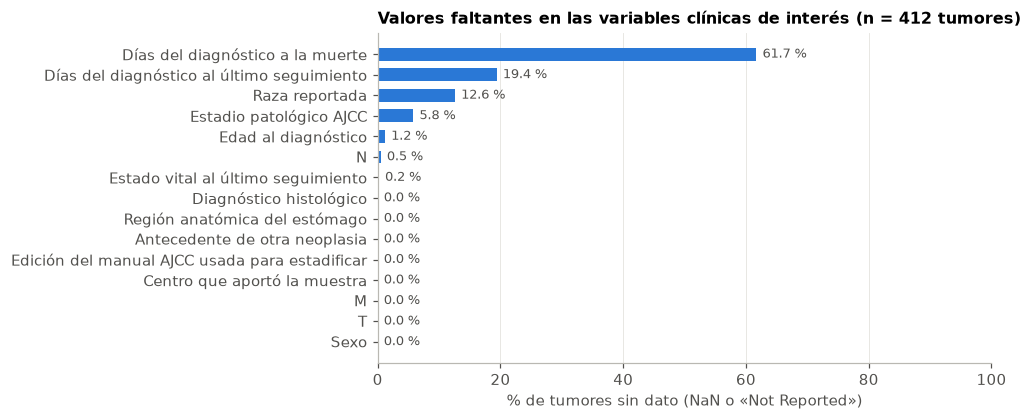

In [10]:
n_nan_expr = int(expr.isna().sum().sum())
print(f"Valores faltantes en la matriz de expresión: {n_nan_expr}")
print(f"Valores exactamente 0 (gen no detectado) en tumores: {100 * (expr[tumores].values == 0).mean():.1f} %")
print(f"Genes con expresión 0 en todos los tumores: {(expr[tumores].sum(axis=1) == 0).sum():,}")
print(f"Tumores sin registro de supervivencia: {len(tumores) - pd.Index(tumores).isin(surv['sample']).sum()}")

falt = dic["% faltante"].sort_values()
fig, ax = plt.subplots(figsize=(7.2, 3.9))
ax.barh([DICCIONARIO[c].split(":")[0].split(" (")[0] for c in falt.index], falt.values, color=AZUL, height=0.62)
for y, v in enumerate(falt.values):
    ax.text(v + 1, y, f"{v:.1f} %", va="center", color=TINTA2, fontsize=8.5)
ax.set_xlabel("% de tumores sin dato (NaN o «Not Reported»)"); ax.set_xlim(0, 100)
ax.set_title("Valores faltantes en las variables clínicas de interés (n = 412 tumores)")
ax.grid(axis="y", visible=False)
plt.show()

**Lectura:**

- **Expresión:** no hay ningún valor faltante. Lo que sí abunda son los ceros (36 % de los valores): genes que no se detectan en esa muestra. Un cero es una medición válida, no un dato perdido, pero 2 430 genes valen cero en todos los tumores y no aportan información.
- **Clínica:** las variables principales están casi completas (edad 1.2 %, estadio 5.8 %). T, N y M aparecen completas, pero incluyen categorías indeterminadas (TX, NX, MX) que en la sección 4 se tratan como faltantes (2–5 %). La raza falta en 13 % y los días hasta el último seguimiento en 19 %; por eso para la supervivencia se usa el archivo ya curado por Xena. Los días hasta la muerte «faltan» en 62 % simplemente porque esos pacientes no habían fallecido.
- **Supervivencia:** 27 de los 412 tumores no tienen registro.

Un faltante menos evidente está en la histología: 156 tumores están clasificados como «Adenocarcinoma, NOS» (*not otherwise specified*), es decir, sin subtipo.

### 3.4 Distribuciones

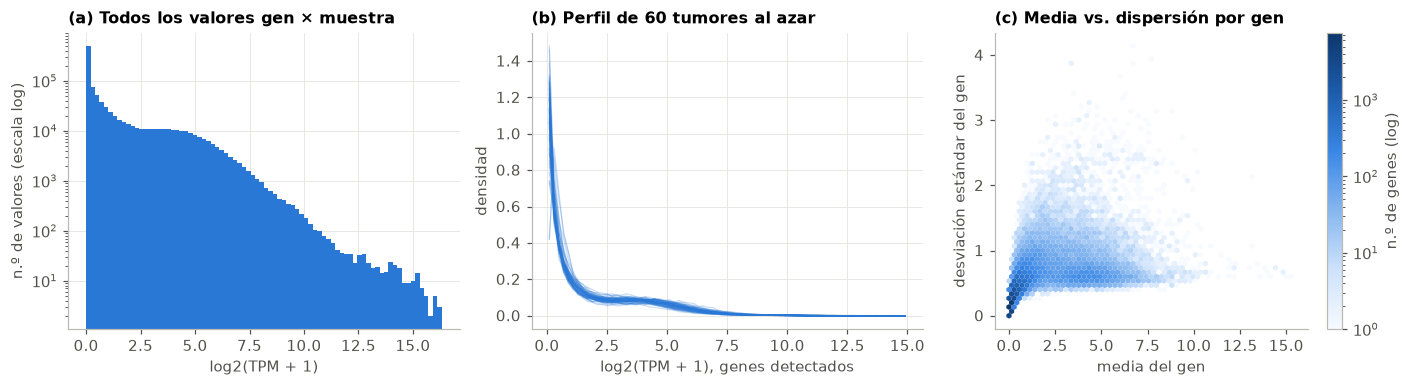

Media por gen: Q1 = 0.07, mediana = 0.29, Q3 = 1.47  ->  la mayoría de los genes está casi apagada


In [11]:
Xt = expr[tumores]
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# (a) todos los valores
vals = Xt.values.ravel()
# Se corrige el error usando replace=True, ya que vals tiene ~264 mil elementos y se piden 1M
muestra_vals = rng.choice(vals, 1_000_000, replace=True)
axes[0].hist(muestra_vals, bins=80, color=AZUL)
axes[0].set_yscale("log"); axes[0].set_xlabel("log2(TPM + 1)"); axes[0].set_ylabel("n.º de valores (escala log)")
axes[0].set_title("(a) Todos los valores gen × muestra")

# (b) densidad por muestra, solo genes detectados
bins = np.linspace(0, 15, 76)
for s in rng.choice(tumores, 60, replace=False):
    v = Xt[s].values; v = v[v > 0]
    h, _ = np.histogram(v, bins=bins, density=True)
    axes[1].plot((bins[:-1] + bins[1:]) / 2, h, color=AZUL, alpha=0.25, lw=0.8)
axes[1].set_xlabel("log2(TPM + 1), genes detectados"); axes[1].set_ylabel("densidad")
axes[1].set_title("(b) Perfil de 60 tumores al azar")

# (c) media vs desviación estándar por gen
media_g, sd_g = Xt.mean(axis=1), Xt.std(axis=1)
hb = axes[2].hexbin(media_g, sd_g, gridsize=55, bins="log", cmap=CMAP_SEQ, mincnt=1, linewidths=0)
axes[2].set_xlabel("media del gen"); axes[2].set_ylabel("desviación estándar del gen")
axes[2].set_title("(c) Media vs. dispersión por gen"); axes[2].grid(False)
fig.colorbar(hb, ax=axes[2], label="n.º de genes (log)")
plt.tight_layout(); plt.show()

q = np.percentile(media_g, [25, 50, 75])
print(f"Media por gen: Q1 = {q[0]:.2f}, mediana = {q[1]:.2f}, Q3 = {q[2]:.2f}  ->  la mayoría de los genes está casi apagada")

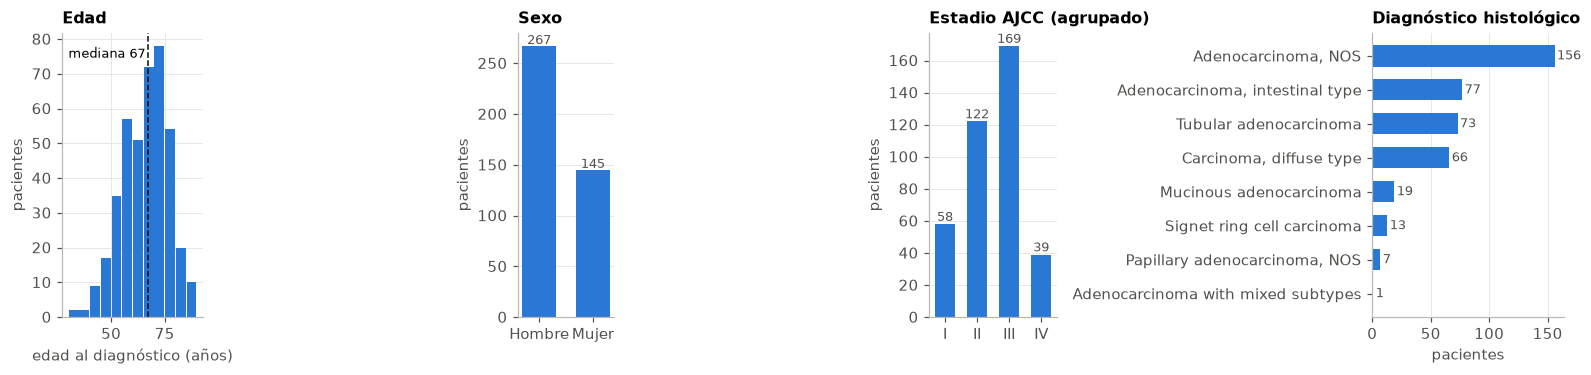

Edad: media 65.6 ± 10.7 años (rango 30–90)
Supervivencia (n = 385): 159 fallecimientos (41 %), mediana de seguimiento 466 días


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.5), gridspec_kw={"width_ratios": [1.1, 0.75, 1.0, 1.5]})

edad = clin_t["age_at_index.demographic"]
axes[0].hist(edad.dropna(), bins=np.arange(30, 95, 5), color=AZUL, rwidth=0.92)
axes[0].axvline(edad.median(), color=TINTA, lw=1, ls="--")
axes[0].text(edad.median() - 1, axes[0].get_ylim()[1] * 0.95, f"mediana {edad.median():.0f}", ha="right", va="top", fontsize=8.5)
axes[0].set_xlabel("edad al diagnóstico (años)"); axes[0].set_ylabel("pacientes"); axes[0].set_title("Edad")

def barras(ax, serie, titulo, horizontal=False, orden=None):
    c = serie.value_counts()
    if orden is not None:
        c = c.reindex(orden).dropna()
    if horizontal:
        c = c.sort_values()
        ax.barh(c.index, c.values, color=AZUL, height=0.62)
        for y, v in enumerate(c.values):
            ax.text(v + 2, y, f"{int(v)}", va="center", fontsize=8.5, color=TINTA2)
        ax.grid(axis="y", visible=False); ax.set_xlabel("pacientes")
    else:
        ax.bar(c.index, c.values, color=AZUL, width=0.62)
        for x, v in enumerate(c.values):
            ax.text(x, v + 2, f"{int(v)}", ha="center", fontsize=8.5, color=TINTA2)
        ax.grid(axis="x", visible=False); ax.set_ylabel("pacientes")
    ax.set_title(titulo)

barras(axes[1], clin_t["gender.demographic"].map({"male": "Hombre", "female": "Mujer"}), "Sexo")
estadio_bruto = clin_t["ajcc_pathologic_stage.diagnoses"].str.extract(r"Stage (IV|III|II|I)")[0]
barras(axes[2], estadio_bruto, "Estadio AJCC (agrupado)", orden=["I", "II", "III", "IV"])
barras(axes[3], clin_t["primary_diagnosis.diagnoses"], "Diagnóstico histológico", horizontal=True)
plt.tight_layout(); plt.show()

sv_t = surv.set_index("sample").reindex(tumores)
print(f"Edad: media {edad.mean():.1f} ± {edad.std():.1f} años (rango {edad.min():.0f}–{edad.max():.0f})")
print(f"Supervivencia (n = {sv_t['OS'].notna().sum()}): {int(sv_t['OS'].sum())} fallecimientos "
      f"({100 * sv_t['OS'].mean():.0f} %), mediana de seguimiento {sv_t['OS.time'].median():.0f} días")

**Lectura de la expresión:**

- **(a)** La distribución es muy asimétrica: un pico enorme en cero y cerca de cero, y una cola larga hasta 17.7 (equivale a más de 200 000 TPM). La mitad de los genes tiene una media menor a 0.29, es decir, está prácticamente apagada.
- **(b)** Los perfiles de los tumores se superponen casi por completo: no hay muestras con una distribución global distinta, señal de que la normalización TPM dejó las muestras comparables.
- **(c)** La dispersión de un gen depende de su nivel de expresión. Los genes casi apagados tienen poca variación (y la que tienen es ruido), mientras que algunos genes de expresión media varían muchísimo entre tumores: esos son los que pueden separar subgrupos.

**Lectura de la clínica:** la cohorte tiene una mediana de 67 años (rango 30–90), 65 % de hombres y predominio de enfermedad localmente avanzada (estadios II–III: 291 de los 388 con estadio conocido). Hay 159 fallecimientos (41 %) con una mediana de seguimiento de 466 días, un seguimiento corto que limitará el análisis de supervivencia.

### 3.5 Detección de valores atípicos

En datos de expresión un valor atípico relevante no es un número extremo aislado (hay millones de valores) sino una **muestra** cuyo perfil completo se aparta del resto, normalmente por problemas de calidad. Se calculan cuatro métricas por tumor y se marcan los que se alejan más de 3.5 desviaciones robustas (basadas en la mediana y la MAD) de la mediana:

1. número de genes detectados,
2. mediana de expresión de los genes expresados,
3. porcentaje de la señal que proviene de genes mitocondriales,
4. correlación media de su perfil con el de los demás tumores.

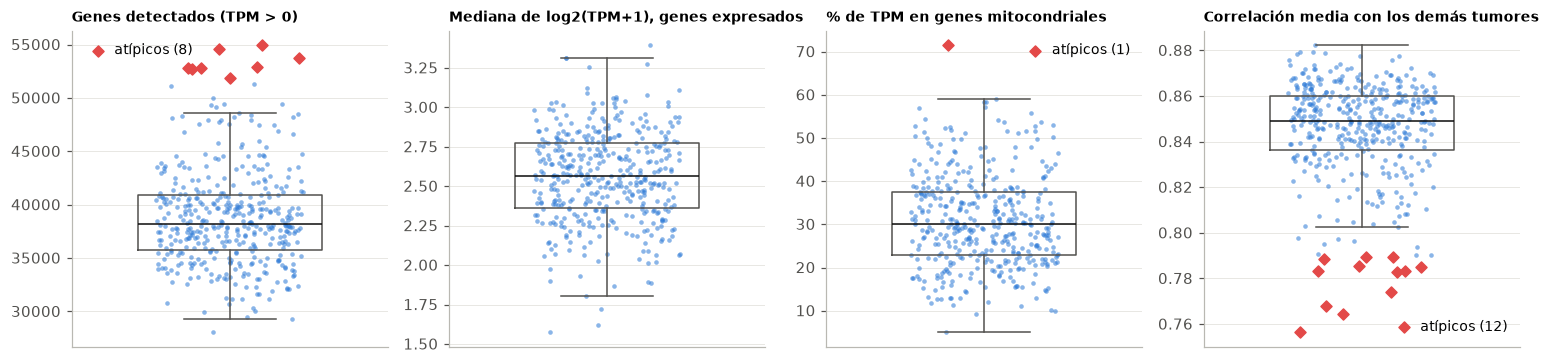

Resumen de las métricas:


,Genes detectados (TPM > 0),"Mediana de log2(TPM+1), genes expresados",% de TPM en genes mitocondriales,Correlación media con los demás tumores
min,28050.00,1.57,5.00,0.76
25%,35793.00,2.36,23.00,0.84
50%,38209.50,2.57,29.98,0.85
75%,40954.25,2.77,37.48,0.86
max,54949.00,3.39,71.51,0.88


Muestras marcadas en al menos una métrica: 20  ·  en dos o más: 1


,Genes detectados (TPM > 0),"Mediana de log2(TPM+1), genes expresados",% de TPM en genes mitocondriales,Correlación media con los demás tumores
TCGA-HU-A4GD-01A,54949,2.63,55.89,0.76


In [13]:
# Métricas de calidad por muestra (solo tumores)
es_mt = (gmap.loc[expr.index, "chrom"] == "chrM").values
tpm_t = np.power(2.0, Xt) - 1
genes_expresados_qc = (Xt >= 1).mean(axis=1) >= 0.2
corr = np.corrcoef(Xt[genes_expresados_qc].values.T)
np.fill_diagonal(corr, np.nan)

qc = pd.DataFrame({
    "Genes detectados (TPM > 0)": (Xt > 0).sum(axis=0),
    "Mediana de log2(TPM+1), genes expresados": Xt[genes_expresados_qc].median(axis=0),
    "% de TPM en genes mitocondriales": 100 * tpm_t[es_mt].sum(axis=0) / tpm_t.sum(axis=0),
    "Correlación media con los demás tumores": np.nanmean(corr, axis=1),
}, index=tumores)

def z_robusto(x):
    mad = np.median(np.abs(x - np.median(x)))
    return (x - np.median(x)) / (1.4826 * mad)
zq = qc.apply(z_robusto)
atipico_qc = zq.abs() > 3.5          # criterio habitual: |z robusto| > 3.5

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, col in zip(axes, qc.columns):
    jitter = rng.uniform(-0.28, 0.28, len(qc))
    m = atipico_qc[col].values
    ax.scatter(jitter[~m], qc[col][~m], s=9, color=AZUL, alpha=0.55, linewidths=0)
    ax.scatter(jitter[m], qc[col][m], s=26, color=ROJO, marker="D", label=f"atípicos ({m.sum()})")
    ax.boxplot(qc[col], positions=[0], widths=0.7, showfliers=False,
               medianprops=dict(color=TINTA), boxprops=dict(color=TINTA2), whiskerprops=dict(color=TINTA2),
               capprops=dict(color=TINTA2))
    ax.set_xticks([]); ax.set_xlim(-0.6, 0.6); ax.set_title(col, fontsize=9, fontweight="bold")
    ax.grid(axis="x", visible=False)
    if m.sum():
        ax.legend(loc="best", handletextpad=0.2)
plt.tight_layout(); plt.show()

print("Resumen de las métricas:")
display(qc.describe().loc[["min", "25%", "50%", "75%", "max"]].round(2))
print(f"Muestras marcadas en al menos una métrica: {int(atipico_qc.any(axis=1).sum())}  ·  en dos o más: {int((atipico_qc.sum(axis=1) >= 2).sum())}")
display(qc[atipico_qc.sum(axis=1) >= 2].round(2))

**Lectura:**

- 20 tumores quedan marcados en alguna métrica, casi todos por tener una correlación algo menor con el resto (0.76–0.80 frente a una mediana de 0.85) o más genes detectados. Solo **uno** (`TCGA-HU-A4GD`) falla en dos métricas a la vez. Son desviaciones moderadas: ninguna muestra es claramente defectuosa.
- La métrica que más llama la atención es la **fracción mitocondrial: va de 5 % a 72 %** del TPM total (mediana 30 %). Como el TPM reparte un millón entre todos los genes, un tumor con mucho ARN mitocondrial tiene artificialmente rebajados todos sus demás genes. Esto se corrige en la sección 4.

**Decisión:** no se elimina ninguna muestra en esta etapa. Las marcadas se vuelven a revisar en el espacio del PCA (sección 5) y se comprueba que quitarlas no cambia los clusters (sección 6.4).

### 3.6 Tumores frente a tejido normal

El archivo incluye 36 muestras de tejido normal. Antes de decidir qué hacer con ellas conviene ver cuánto pesan en la variación global.

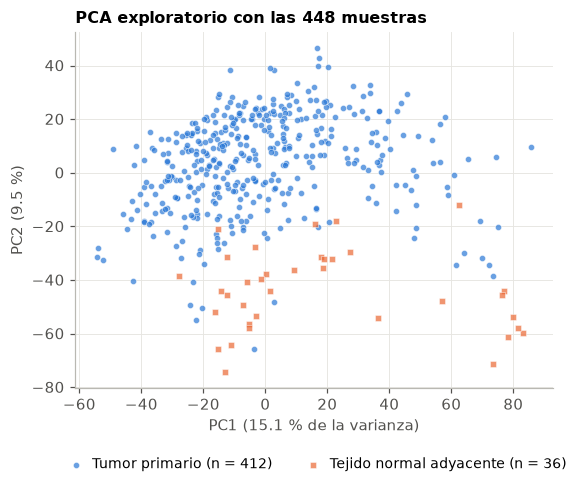

In [14]:
# Vistazo global con TODAS las muestras: ¿qué domina la variación si se mezclan tumores y normales?
# Se eliminan las filas (genes) con valores faltantes (NaN) para evitar el error en el PCA
Xall = expr.loc[genes_expresados_qc].dropna()
top_all = Xall.var(axis=1).sort_values(ascending=False).index[:5000]
Zall = Xall.loc[top_all].T
Zall = (Zall - Zall.mean()) / Zall.std()
pca_all = PCA(n_components=2, svd_solver="full").fit(Zall)
pc_all = pca_all.transform(Zall)

fig, ax = plt.subplots(figsize=(5.6, 4.2))
for etiqueta, color, marc in [("Tumor primario", AZUL, "o"), ("Tejido normal adyacente", NARANJA, "s")]:
    m = (tipo == etiqueta).values
    ax.scatter(pc_all[m, 0], pc_all[m, 1], s=16, color=color, marker=marc, alpha=0.7,
               edgecolors="white", linewidths=0.4, label=f"{etiqueta} (n = {m.sum()})")
ax.set_xlabel(f"PC1 ({100 * pca_all.explained_variance_ratio_[0]:.1f} % de la varianza)")
ax.set_ylabel(f"PC2 ({100 * pca_all.explained_variance_ratio_[1]:.1f} %)")
ax.set_title("PCA exploratorio con las 448 muestras")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, handletextpad=0.2)
plt.show()

**Lectura:** las muestras normales se concentran en la parte inferior del plano y se separan de la mayoría de los tumores a lo largo de PC2. Si se dejaran en el análisis, cualquier algoritmo de clustering dedicaría uno de sus grupos a «tejido normal», que no es la pregunta de este trabajo. Por eso el análisis se hace **solo con los 412 tumores primarios**.

## 4. Preparación y tratamiento de los datos

Cada decisión de esta sección cambia lo que el PCA y el clustering pueden ver, así que se justifican una por una.

| # | Decisión | Justificación |
|---|---|---|
| 1 | **Usar solo los 412 tumores primarios** | El objetivo es encontrar subgrupos *dentro* de la enfermedad. Con los normales incluidos, la diferencia tumor/normal dominaría la estructura (sección 3.6). |
| 2 | **No eliminar muestras atípicas** | Ninguna es claramente defectuosa. Se verifica después que los resultados no dependen de ellas. |
| 3 | **Re-normalizar el TPM sin los genes mitocondriales** | La fracción mitocondrial varía de 5 % a 72 % entre tumores. Como el TPM es una proporción, eso desplaza todos los genes nucleares de una muestra a la vez y crearía diferencias globales que no son biología del tumor. Se quitan los 37 genes del cromosoma mitocondrial y se re-escala cada muestra a un millón. |
| 4 | **Eliminar genes poco expresados** (TPM ≥ 1 en menos del 20 % de los tumores) | Más de la mitad de los genes está casi apagada; su variación es ruido de conteo. Se usa 20 % y no un umbral más alto para conservar genes activos solo en un subgrupo de tumores, que son justo los interesantes. |
| 5 | **Eliminar los genes del cromosoma Y y *XIST*** | Su expresión depende casi por completo del sexo del paciente (correlación de hasta 0.92). Están entre los genes más variables y harían que el algoritmo agrupara por sexo. |
| 6 | **Eliminar ARN pequeños** (genes de menos de 200 pares de bases) | El RNA-seq de TCGA se diseñó para ARN mensajero; los microARN, snoARN y ARNt se capturan mal y, al dividir entre una longitud muy corta, unas pocas lecturas producen TPM enormes y erráticos. El archivo de mapeo no indica el tipo de gen, así que se usa la longitud como aproximación. |
| 7 | **Eliminar pseudogenes mitocondriales y ribosomales, y loci sin símbolo oficial** | Los pseudogenes son copias casi idénticas de genes muy expresados: su señal son lecturas mal asignadas. En pruebas sin este filtro, uno de los primeros componentes principales quedaba dominado por pseudogenes mitocondriales, sin significado biológico. Los loci sin nombre (tipo `AC012345.1`) son en su mayoría ARN no codificantes poco caracterizados que no podrían interpretarse. |
| 8 | **Quedarse con los 5 000 genes de mayor varianza** | Un gen que no cambia entre tumores no puede separarlos y solo añade ruido a las distancias. Es el filtro de «baja varianza» habitual en este tipo de estudios. El número exacto es una elección; en la sección 6.4 se prueba con 2 000 y 10 000. |
| 9 | **Estandarizar cada gen** (media 0, desviación 1) | Los datos ya vienen en logaritmo, que comprime los valores extremos. Aun así, sin estandarizar, el PCA y K-means estarían dominados por un puñado de genes con varianza enorme (*PGC*, *GKN1*, *LIPF*…). Tras estandarizar, todos los genes pesan lo mismo y lo que cuenta es el patrón conjunto. |
| 10 | **Valores faltantes** | La expresión no tiene faltantes, así que no hay nada que imputar. En la clínica, «Not Reported» y las categorías indeterminadas (TX, NX, MX) se recodifican como faltantes y cada prueba usa los pacientes con dato disponible; no se imputa porque las variables clínicas no entran al clustering y una imputación solo inventaría asociaciones. |
| 11 | **Recodificar las variables clínicas** | Los subestadios (IIIA, IIIB…) se agrupan en I–IV y los ocho diagnósticos histológicos en las categorías de Lauren, para tener grupos con tamaño suficiente para comparar. |

In [15]:
# ---------- Paso 1. Solo tumores primarios ----------
X = expr[tumores]

# ---------- Paso 2. Re-normalizar los TPM sin genes mitocondriales ----------
tpm = np.power(2.0, X) - 1
tpm_nuc = tpm.loc[~es_mt]
tpm_nuc = tpm_nuc / tpm_nuc.sum(axis=0) * 1e6
logx = np.log2(tpm_nuc + 1)
ann = gmap.loc[logx.index].copy()
ann["longitud"] = ann["chromEnd"] - ann["chromStart"]

# ---------- Paso 3. Filtros de genes ----------
pasos = [("Genes en la matriz original", len(expr))]
pasos.append(("– genes mitocondriales (chrM)", len(logx)))

expresado = (logx >= 1).mean(axis=1) >= 0.20                 # TPM >= 1 en al menos 20 % de los tumores
mask = expresado.copy();                                      pasos.append(("– baja expresión (TPM ≥ 1 en < 20 % de tumores)", int(mask.sum())))
mask &= (ann["chrom"] != "chrY") & (ann["gene"] != "XIST");   pasos.append(("– cromosoma Y y XIST (sexo)", int(mask.sum())))
mask &= ann["longitud"] >= 200;                               pasos.append(("– ARN pequeños (< 200 pb: miARN, snoARN, ARNt…)", int(mask.sum())))
pseudo_mt = ann["gene"].str.match(r"^MT(ND|CO|ATP|CYB|RNR)\w*P\d+$") | ann["gene"].str.match(r"^MTRNR2L\d+$")
pseudo_rp = ann["gene"].str.match(r"^RP[SL]\d+[A-Z]?\d*P\d+$")
mask &= ~(pseudo_mt | pseudo_rp);                             pasos.append(("– pseudogenes mitocondriales y ribosomales", int(mask.sum())))
sin_nombre = ann["gene"].str.match(r"^[A-Z]{1,3}\d{5,6}\.\d+$")
mask &= ~sin_nombre;                                          pasos.append(("– loci sin símbolo oficial (p. ej. AC012345.1)", int(mask.sum())))

Xf = logx.loc[mask]
embudo = pd.DataFrame(pasos, columns=["Paso", "Genes restantes"])
embudo["Eliminados"] = (-embudo["Genes restantes"].diff()).fillna(0).astype(int)
display(embudo)

# Símbolo de cada gen (para etiquetar resultados). Si un símbolo se repite se conserva el más expresado.
simbolo = ann.loc[Xf.index, "gene"]
print(f"Matriz filtrada: {Xf.shape[0]:,} genes x {Xf.shape[1]} tumores   ·   símbolos repetidos: {int(simbolo.duplicated().sum())}")

,Paso,Genes restantes,Eliminados
0,Genes en la matriz original,60660,0
1,– genes mitocondriales (chrM),60623,37
2,– baja expresión (TPM ≥ 1 en < 20 % de tumores),25587,35036
3,– cromosoma Y y XIST (sexo),25554,33
4,"– ARN pequeños (< 200 pb: miARN, snoARN, ARNt…)",23546,2008
5,– pseudogenes mitocondriales y ribosomales,22930,616
6,– loci sin símbolo oficial (p. ej. AC012345.1),18500,4430


Matriz filtrada: 18,500 genes x 412 tumores   ·   símbolos repetidos: 52


In [16]:
# Evidencia para dos de las decisiones anteriores
sexo_bin = (clin_t["gender.demographic"] == "male").astype(float).values
cand = logx.loc[expresado]
r_sexo = cand.T.corrwith(pd.Series(sexo_bin, index=tumores))
tab_sexo = pd.DataFrame({"gen": ann.loc[r_sexo.index, "gene"], "cromosoma": ann.loc[r_sexo.index, "chrom"],
                         "r con sexo (hombre = 1)": r_sexo.round(2)})
tab_sexo = tab_sexo[tab_sexo["r con sexo (hombre = 1)"].abs() > 0.5].sort_values("r con sexo (hombre = 1)")
print("Genes cuya expresión está fuertemente correlacionada con el sexo (|r| > 0.5):")
display(tab_sexo.reset_index(drop=True))

pct_mt = qc["% de TPM en genes mitocondriales"]
print(f"\nFracción mitocondrial del TPM: mediana {pct_mt.median():.0f} %, rango {pct_mt.min():.0f}–{pct_mt.max():.0f} %")
print(f"Sin re-normalizar, el tumor con más ARN mitocondrial tendría todos sus genes nucleares "
      f"desplazados {np.log2((100 - pct_mt.min()) / (100 - pct_mt.max())):.1f} unidades log2 respecto al que tiene menos.")

Genes cuya expresión está fuertemente correlacionada con el sexo (|r| > 0.5):


,gen,cromosoma,r con sexo (hombre = 1)
0,XIST,chrX,-0.88
1,TMSB4Y,chrY,0.54
2,AC006157.1,chrY,0.58
3,LINC00278,chrY,0.60
4,AC010889.1,chrY,0.67
5,PRKY,chrY,0.76
6,USP9Y,chrY,0.76
7,TXLNGY,chrY,0.77
8,UTY,chrY,0.78
9,NLGN4Y,chrY,0.79



Fracción mitocondrial del TPM: mediana 30 %, rango 5–72 %
Sin re-normalizar, el tumor con más ARN mitocondrial tendría todos sus genes nucleares desplazados 1.7 unidades log2 respecto al que tiene menos.


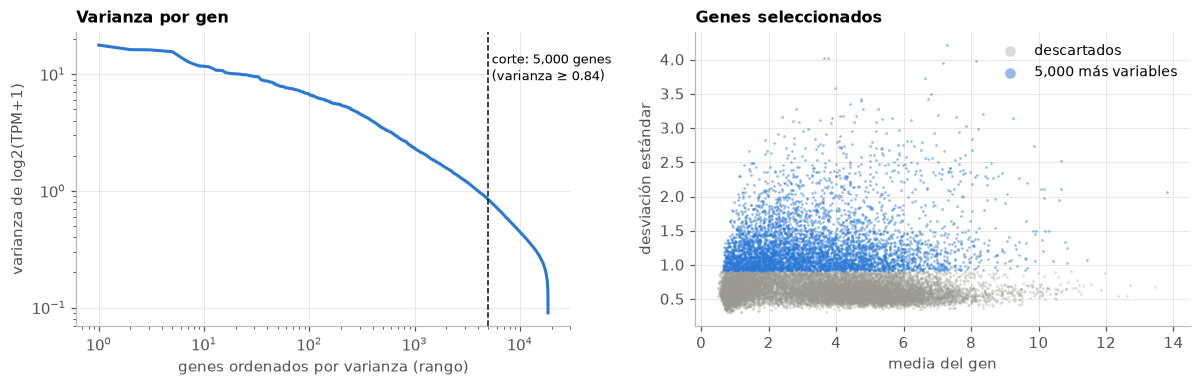

Los 5,000 genes seleccionados concentran el 63 % de la varianza total.
20 genes más variables: PGC, GKN1, LIPF, OLFM4, REG1A, TFF2, REG3A, DES, MUC6, REG4, BPIFB1, KRT20, MUC5AC, GKN2, PSCA, PIGR, PLA2G2A, IGHV5-10-1, SPINK4, MUCL3

Matriz de entrada al PCA: 412 tumores x 5,000 genes (media 0, desviación 1 por gen)


In [17]:
# ---------- Paso 4. Genes más variables ----------
N_GENES = 5000
varianza = Xf.var(axis=1).sort_values(ascending=False)
# Si hay menos genes que el límite deseado, nos quedamos con todos los disponibles
N_GENES = min(N_GENES, len(varianza))
hvg = varianza.index[:N_GENES]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(np.arange(1, len(varianza) + 1), varianza.values, color=AZUL, lw=2)
axes[0].axvline(N_GENES, color=TINTA, ls="--", lw=1)
axes[0].text(N_GENES * 1.08, varianza.iloc[0] * 0.5, f"corte: {N_GENES:,} genes\n(varianza ≥ {varianza.iloc[N_GENES - 1]:.2f})", fontsize=8.5)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("genes ordenados por varianza (rango)"); axes[0].set_ylabel("varianza de log2(TPM+1)")
axes[0].set_title("Varianza por gen")

m_sel = Xf.index.isin(hvg)
axes[1].scatter(Xf.mean(axis=1)[~m_sel], Xf.std(axis=1)[~m_sel], s=3, color=GRIS, alpha=0.35, linewidths=0, label="descartados")
axes[1].scatter(Xf.mean(axis=1)[m_sel], Xf.std(axis=1)[m_sel], s=3, color=AZUL, alpha=0.5, linewidths=0, label=f"{N_GENES:,} más variables")
axes[1].set_xlabel("media del gen"); axes[1].set_ylabel("desviación estándar")
axes[1].set_title("Genes seleccionados"); axes[1].legend(markerscale=4, loc="upper right")
plt.tight_layout(); plt.show()

print(f"Los {N_GENES:,} genes seleccionados concentran el {100 * varianza.iloc[:N_GENES].sum() / varianza.sum():.0f} % de la varianza total.")
print("20 genes más variables:", ", ".join(simbolo[hvg[:20]]))

# ---------- Paso 5. Estandarización (z-score por gen) ----------
Z = Xf.loc[hvg].T                      # filas = tumores, columnas = genes
Z = (Z - Z.mean()) / Z.std()
print(f"\nMatriz de entrada al PCA: {Z.shape[0]} tumores x {Z.shape[1]:,} genes (media 0, desviación 1 por gen)")

In [18]:
# ---------- Paso 6. Variables clínicas recodificadas ----------
meta = pd.DataFrame(index=tumores)
meta["Edad"] = clin_t["age_at_index.demographic"]
meta["Sexo"] = clin_t["gender.demographic"].map({"male": "Hombre", "female": "Mujer"})
meta["Raza"] = clin_t["race.demographic"].map({"white": "Blanca", "asian": "Asiática",
                                               "black or african american": "Negra/afroamericana"})
meta["Estadio"] = clin_t["ajcc_pathologic_stage.diagnoses"].str.extract(r"Stage (IV|III|II|I)")[0]
meta["T"] = clin_t["ajcc_pathologic_t.diagnoses"].str.extract(r"(T[1-4])")[0]
meta["N"] = clin_t["ajcc_pathologic_n.diagnoses"].str.extract(r"(N[0-3])")[0]
meta["M"] = clin_t["ajcc_pathologic_m.diagnoses"].str.extract(r"(M[01])")[0]
meta["Histología"] = clin_t["primary_diagnosis.diagnoses"].map({
    "Adenocarcinoma, intestinal type": "Intestinal", "Tubular adenocarcinoma": "Intestinal",
    "Papillary adenocarcinoma, NOS": "Intestinal",
    "Carcinoma, diffuse type": "Difuso", "Signet ring cell carcinoma": "Difuso",
    "Mucinous adenocarcinoma": "Mucinoso",
    "Adenocarcinoma, NOS": "No especificado", "Adenocarcinoma with mixed subtypes": "No especificado"})
meta["Región"] = clin_t["tissue_or_organ_of_origin.diagnoses"].map({
    "Cardia, NOS": "Cardias", "Fundus of stomach": "Fondo/cuerpo", "Body of stomach": "Fondo/cuerpo",
    "Gastric antrum": "Antro/píloro", "Pylorus": "Antro/píloro"})
centro = clin_t["name.tissue_source_site"]
grandes = centro.value_counts()[lambda s: s >= 15].index
meta["Centro"] = centro.where(centro.isin(grandes), "Otros (< 15 muestras)")
meta["OS"] = sv_t["OS"]; meta["OS_dias"] = sv_t["OS.time"]
meta["% mitocondrial"] = pct_mt

def describir(c):
    if c == "OS":
        return f"{int(meta[c].sum())} fallecimientos, {int((meta[c] == 0).sum())} censurados"
    if meta[c].dtype.kind in "biuf":
        return f"mediana {meta[c].median():.0f} (rango {meta[c].min():.0f}–{meta[c].max():.0f})"
    return ", ".join(f"{k} ({v})" for k, v in meta[c].value_counts().items())
resumen_meta = pd.DataFrame({"n con dato": meta.notna().sum(), "% faltante": (100 * meta.isna().mean()).round(1),
                             "Categorías (n) o resumen": [describir(c) for c in meta.columns]})
display(resumen_meta)

,n con dato,% faltante,Categorías (n) o resumen
Edad,407,1.2,mediana 67 (rango 30–90)
Sexo,412,0.0,"Hombre (267), Mujer (145)"
Raza,359,12.9,"Blanca (260), Asiática (87), Negra/afroamericana (12)"
Estadio,388,5.8,"III (169), II (122), I (58), IV (39)"
T,404,1.9,"T3 (181), T4 (113), T2 (88), T1 (22)"
N,393,4.6,"N0 (124), N1 (109), N3 (82), N2 (78)"
M,391,5.1,"M0 (365), M1 (26)"
Histología,412,0.0,"No especificado (157), Intestinal (157), Difuso (79), Mucinoso (19)"
Región,394,4.4,"Antro/píloro (149), Fondo/cuerpo (146), Cardias (99)"
Centro,412,0.0,"Asterand (130), Otros (< 15 muestras) (68), Barretos Cancer Hospital (62), Greater Poland Cancer Center (40), National Cancer Center Korea (34), Indivumed (33), ILSBio (29), University of Pittsburgh (16)"


**Resultado de la preparación:**

- El embudo de filtros reduce los 60 660 genes a **18 500**. El filtro que más elimina es el de baja expresión (35 036 genes).
- La tabla de genes correlacionados con el sexo confirma la decisión 5: los 15 genes con |r| > 0.5 son *XIST* y genes del cromosoma Y.
- Sin la re-normalización, el tumor con más ARN mitocondrial habría tenido todos sus genes nucleares desplazados 1.7 unidades log2 (un factor de 3.3) respecto al que tiene menos.
- Los **5 000 genes más variables concentran el 63 % de la varianza total** de los 18 500. Encabezan la lista genes propios de la mucosa gástrica (*PGC*, *GKN1*, *LIPF*, *TFF2*, *MUC6*, *MUC5AC*), de diferenciación intestinal (*OLFM4*, *REG4*, *KRT20*), de músculo liso (*DES*) y de células plasmáticas (inmunoglobulinas). Es decir, lo que más varía entre tumores es **cuánto conservan del estómago normal, cuánto se parecen al intestino y cuánto tejido no tumoral contienen**.
- Variables clínicas recodificadas: la histología queda en Intestinal (157), Difuso (79), Mucinoso (19) y No especificado (157).

La matriz que entra al PCA tiene **412 tumores × 5 000 genes estandarizados**.

## 5. Reducción de dimensionalidad mediante PCA

Aun con 5 000 genes hay 12 veces más variables que tumores, y muchos genes se mueven juntos porque participan en el mismo proceso. El **Análisis de Componentes Principales (PCA)** aprovecha esa redundancia: busca combinaciones lineales de genes (componentes) que capturan la mayor varianza posible, cada una independiente de las anteriores. Sirve para tres cosas:

1. **explorar**: ver los tumores en 2 dimensiones;
2. **entender**: los genes con más peso en un componente dicen qué proceso representa;
3. **preparar el clustering**: agrupar sobre pocos componentes en vez de 5 000 genes reduce el ruido y evita que las distancias pierdan sentido en alta dimensión.

### 5.1 Varianza explicada

Además del gráfico de sedimentación (*scree plot*) se hace un **análisis paralelo**: se permuta cada gen por separado, lo que destruye las correlaciones entre genes, y se repite el PCA 20 veces. Un componente real solo es señal si explica más varianza que la que aparece por azar en los datos permutados.

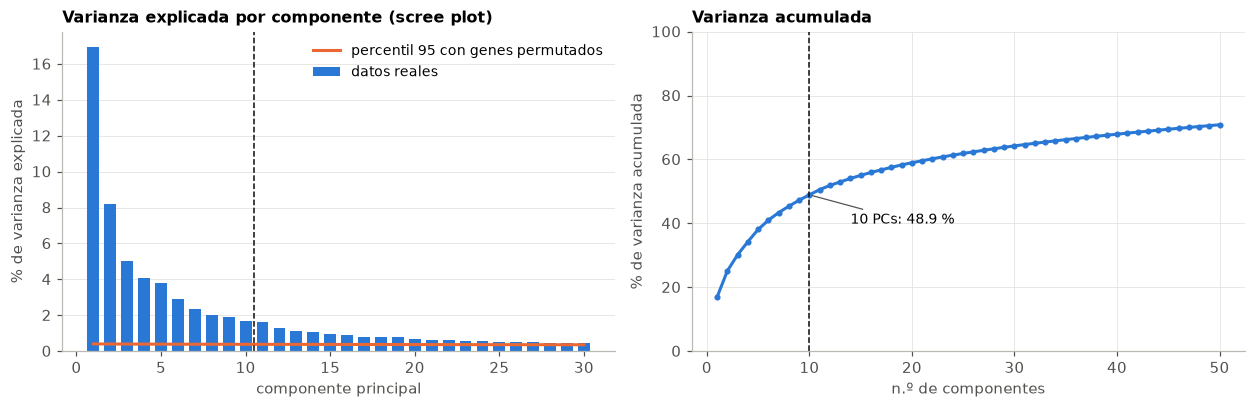

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
% varianza,16.95,8.18,5.04,4.1,3.82,2.92,2.36,2.01,1.88,1.67,1.62,1.32
% acumulado,17.00,25.10,30.20,34.3,38.10,41.00,43.40,45.40,47.30,48.90,50.60,51.90


Componentes para llegar a 50 / 60 / 70 % de la varianza: 11 / 22 / 47
Componentes que superan el umbral de ruido del análisis paralelo: 36


In [19]:
# Rellenamos los valores faltantes de Z con 0 (que equivale a la media tras la estandarización)
Z_imputed = Z.fillna(0)

pca = PCA(n_components=50, svd_solver="full").fit(Z_imputed)
# Convención de signo fija (el signo de un componente es arbitrario): el gen con mayor peso absoluto queda positivo
signos = np.sign(pca.components_[np.arange(50), np.abs(pca.components_).argmax(axis=1)])
pca.components_ *= signos[:, None]
scores = pd.DataFrame(pca.transform(Z_imputed), index=tumores, columns=[f"PC{i + 1}" for i in range(50)])
evr = pca.explained_variance_ratio_

# Análisis paralelo: ¿cuánta varianza explicaría cada componente si los genes fueran independientes?
rng = np.random.default_rng(SEED)
n_perm, nulo = 20, []
for _ in range(n_perm):
    Zp = rng.permuted(Z_imputed.values, axis=0)                      # se permuta cada gen por separado
    s = np.linalg.svd(Zp - Zp.mean(axis=0), compute_uv=False)
    nulo.append((s ** 2 / (s ** 2).sum())[:50])
umbral = np.percentile(np.array(nulo), 95, axis=0)
n_sobre_ruido = int(np.argmax(evr <= umbral)) if (evr <= umbral).any() else 50

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
k = np.arange(1, 31)
axes[0].bar(k, 100 * evr[:30], color=AZUL, width=0.7, label="datos reales")
axes[0].plot(k, 100 * umbral[:30], color=NARANJA, lw=2, label="percentil 95 con genes permutados")
axes[0].axvline(10.5, color=TINTA, ls="--", lw=1)
axes[0].set_xlabel("componente principal"); axes[0].set_ylabel("% de varianza explicada")
axes[0].set_title("Varianza explicada por componente (scree plot)"); axes[0].legend(loc="upper right")
axes[0].grid(axis="x", visible=False)

acum = 100 * np.cumsum(evr)
axes[1].plot(np.arange(1, 51), acum, color=AZUL, lw=2, marker="o", ms=3)
axes[1].axvline(10, color=TINTA, ls="--", lw=1)
axes[1].annotate(f"10 PCs: {acum[9]:.1f} %", (10, acum[9]), xytext=(14, acum[9] - 9), fontsize=9,
                 arrowprops=dict(arrowstyle="-", color=TINTA2, lw=0.8))
axes[1].set_xlabel("n.º de componentes"); axes[1].set_ylabel("% de varianza acumulada"); axes[1].set_ylim(0, 100)
axes[1].set_title("Varianza acumulada")
plt.tight_layout(); plt.show()

tab_var = pd.DataFrame({"% varianza": (100 * evr[:12]).round(2), "% acumulado": acum[:12].round(1)},
                       index=[f"PC{i}" for i in range(1, 13)]).T
display(tab_var)
print(f"Componentes para llegar a 50 / 60 / 70 % de la varianza: "
      f"{int(np.searchsorted(acum, 50) + 1)} / {int(np.searchsorted(acum, 60) + 1)} / {int(np.searchsorted(acum, 70) + 1)}")
print(f"Componentes que superan el umbral de ruido del análisis paralelo: {n_sobre_ruido}{'+' if n_sobre_ruido == 50 else ''}")

**Lectura:**

- **PC1 explica el 17.0 % de la varianza y PC2 el 8.2 %**; juntos, una cuarta parte. A partir de ahí la contribución cae deprisa: PC3–PC5 aportan entre 5.0 % y 3.8 %, y a partir de PC10 cada componente aporta menos del 1.7 %.
- La varianza está **muy repartida**: 10 componentes llegan al 48.9 %, pero hacen falta 22 para el 60 % y 47 para el 70 %. Es normal en transcriptómica: hay muchos procesos pequeños y ruido de medición independiente en cada gen.
- El análisis paralelo indica que los primeros **36 componentes** superan el nivel de ruido. Hay señal más allá de PC10, pero en porciones muy pequeñas.

### 5.2 Número de componentes seleccionado: 10

No existe un único criterio correcto, así que se combinan varios:

| Criterio | Qué sugiere |
|---|---|
| Codo del *scree plot* | La caída fuerte termina entre PC5 y PC6 y la curva se aplana hacia PC10. |
| Varianza acumulada | No hay un número pequeño que explique «casi todo»; pedir 70 % exigiría 47 componentes. Este criterio por sí solo no es útil aquí. |
| Análisis paralelo | Hasta 36 componentes contienen señal: marca un máximo, no un óptimo. |
| Interpretabilidad | Los primeros 5–6 componentes tienen una lectura biológica clara (sección 5.4). |
| Robustez | Los clusters casi no cambian si se usan 8, 15 o 20 componentes (sección 6.4). |

Se eligen **10 componentes**: incluyen todos los que tienen una interpretación clara, conservan la mitad de la varianza y dejan fuera 4 990 dimensiones dominadas por ruido. Usar 36 añadiría muchas dimensiones de poca señal donde las distancias entre tumores se vuelven menos informativas. Como los *scores* no se re-escalan, cada componente pesa en las distancias en proporción a la varianza que explica.

### 5.3 Qué representa cada componente y visualización

Las siguientes celdas muestran: (1) los genes con más peso en cada componente, (2) qué variables clínicas o técnicas se asocian con cada uno, (3) los tumores proyectados en los primeros componentes y (4) los tumores atípicos en este espacio.

In [20]:
N_PCS = 10
P = scores.iloc[:, :N_PCS]

# Genes con mayor peso en cada componente
cargas = pd.DataFrame(pca.components_[:N_PCS].T, index=simbolo[hvg].values, columns=P.columns)
filas = []
for pc in cargas.columns[:6]:
    orden = cargas[pc].sort_values()
    filas.append({"Componente": pc, "% var.": round(100 * evr[int(pc[2:]) - 1], 1),
                  "Genes con peso más POSITIVO": ", ".join(orden.index[::-1][:12]),
                  "Genes con peso más NEGATIVO": ", ".join(orden.index[:12])})
display(pd.DataFrame(filas).set_index("Componente"))

,% var.,Genes con peso más POSITIVO,Genes con peso más NEGATIVO
Componente,,,
PC1,17.0,"BOC, RNF150, ZCCHC24, FBXL7, NAP1L3, CLIP3, MPDZ, NHSL2, CNRIP1, DDR2, JAM2, SYNE1","UBE2T, CDCA8, CCNB1, BIRC5, RAB25, CKS2, RRM2, MELK, CDK1, CDC20, SKA3, HJURP"
PC2,8.2,"SLAMF7, CD3D, GZMA, CD74, NKG7, SIRPG, HLA-DRA, IL2RB, CD2, CXCR6, CCL5, CD3E","NINL, SYT7, OBSL1, BMP7, TMEM198, CDKN1C, MARK1, OSBP2, TSPY26P, STX1A, WNK2, NKD2"
PC3,5.0,"LRRC66, SYTL2, CDHR5, MUC17, FAM83E, SLC44A4, NR1I2, TSPAN8, GCNT3, MUC3A, MYO1A, LRRC31","CAMK2N2, CTXN1, TCEA2, NME4, NAT14, UBE2S, CADM4, MLLT11, IER5L, FAM171A2, H19, NAT8L"
PC4,4.1,"MYOF, S100A6, FHL2, ANXA1, ITGB4, SERPINB5, LURAP1L, NBL1, ITGA2, AHNAK2, GPRC5A, ADAM9","FGA, APOA1, SOAT2, APOH, TTR, CTD-3080P12.3, LINC01996, SMLR1, APOC3, GSTA2, SLC23A1, RGN"
PC5,3.8,"ADAMTS2, BUB1, HK3, TPX2, CDCA5, ADAMTS12, GTSE1, SNX10, KIF23, KIFC1, KIF20A, MKI67","VSIG2, VSIG1, CYSTM1, FAM189A2, ALDH3A1, AKR1B10P1, FAM177B, AKR1B10, GCNT4, MAL, ANXA10, LGALS9B"
PC6,2.9,"MYB, STXBP6, KHK, ZNF710-AS1, GAU1, CCND2, BCL11A, ASCL2, ALDH1B1, MALRD1, CDX1, UBE2V2P1","CLIC3, TRPV4, TM4SF1, GNA15, LYPD2, PSCA, WNT7B, MDFI, DKK1, UPK3B, CXCL17, FNDC4"


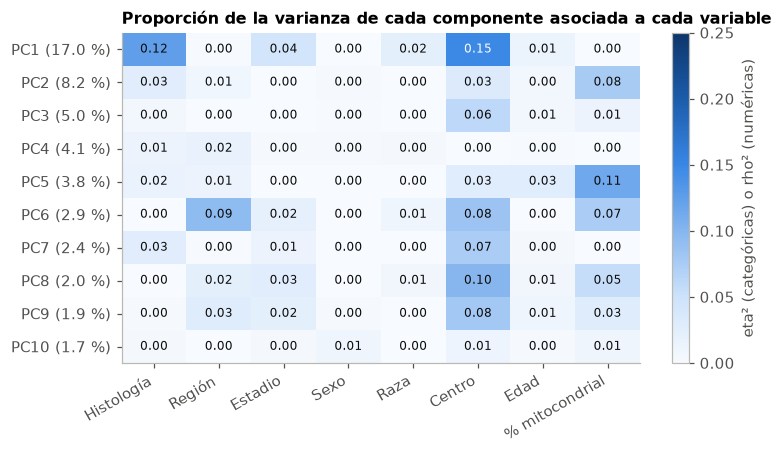

In [21]:
# ¿Con qué variables clínicas o técnicas se asocia cada componente?
# eta² = proporción de la varianza del componente explicada por la variable (Kruskal-Wallis); para numéricas, rho²
def eta2_kw(valores, grupos):
    ok = grupos.notna().values & ~np.isnan(valores)
    g = [valores[ok][grupos[ok].values == c] for c in pd.unique(grupos[ok])]
    g = [x for x in g if len(x) >= 5]
    if len(g) < 2:
        return np.nan
    H = stats.kruskal(*g)[0]; n = sum(len(x) for x in g)
    return max(0.0, (H - len(g) + 1) / (n - len(g)))

vars_cat = ["Histología", "Región", "Estadio", "Sexo", "Raza", "Centro"]
vars_num = ["Edad", "% mitocondrial"]
asoc = pd.DataFrame(index=P.columns, columns=vars_cat + vars_num, dtype=float)
for pc in P.columns:
    for v in vars_cat:
        asoc.loc[pc, v] = eta2_kw(P[pc].values, meta[v])
    for v in vars_num:
        ok = meta[v].notna()
        asoc.loc[pc, v] = stats.spearmanr(P.loc[ok, pc], meta.loc[ok, v])[0] ** 2

fig, ax = plt.subplots(figsize=(7.6, 3.9))
im = ax.imshow(asoc.values.astype(float), cmap=CMAP_SEQ, vmin=0, vmax=0.25, aspect="auto")
ax.set_xticks(range(asoc.shape[1])); ax.set_xticklabels(asoc.columns, rotation=30, ha="right")
ax.set_yticks(range(asoc.shape[0])); ax.set_yticklabels([f"{pc} ({100 * evr[i]:.1f} %)" for i, pc in enumerate(asoc.index)])
for i in range(asoc.shape[0]):
    for j in range(asoc.shape[1]):
        v = asoc.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.14 else TINTA)
ax.grid(False); ax.set_title("Proporción de la varianza de cada componente asociada a cada variable")
fig.colorbar(im, ax=ax, label="eta² (categóricas) o rho² (numéricas)")
plt.show()

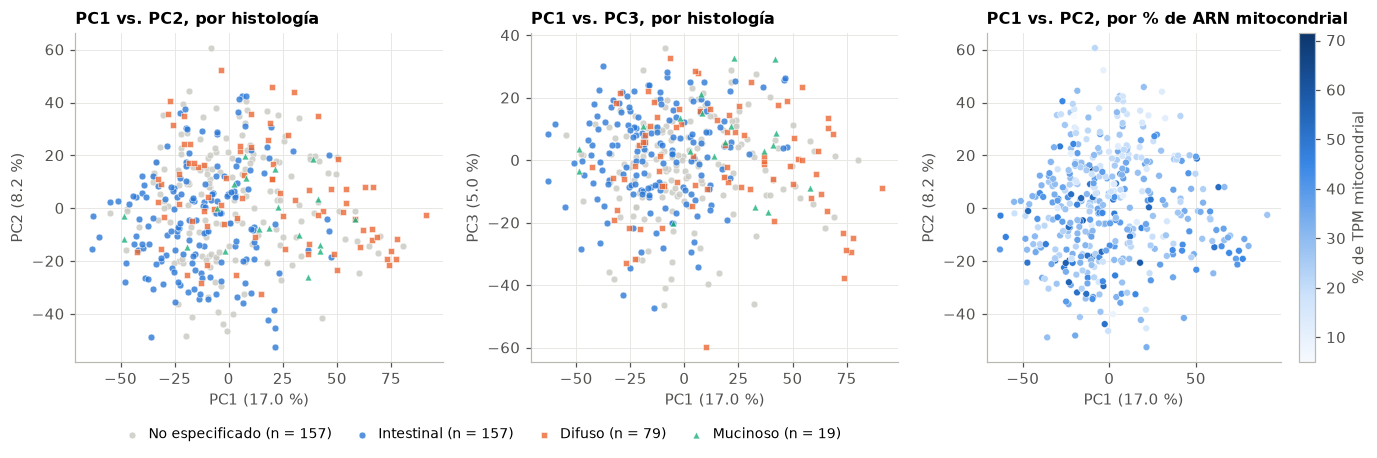

In [22]:
# Visualización en baja dimensión: PC1–PC2 y PC1–PC3, coloreando por histología
COL_HIST = {"Intestinal": "#2a78d6", "Difuso": "#eb6834", "Mucinoso": "#1baf7a", "No especificado": "#c9c8c2"}
MARC_HIST = {"Intestinal": "o", "Difuso": "s", "Mucinoso": "^", "No especificado": "o"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
fig.subplots_adjust(wspace=0.24, bottom=0.2)
for ax, (a, b) in zip(axes[:2], [("PC1", "PC2"), ("PC1", "PC3")]):
    for h in ["No especificado", "Intestinal", "Difuso", "Mucinoso"]:
        m = (meta["Histología"] == h).values
        ax.scatter(P.loc[m, a], P.loc[m, b], s=20, color=COL_HIST[h], marker=MARC_HIST[h], alpha=0.8,
                   edgecolors="white", linewidths=0.4, label=f"{h} (n = {m.sum()})")
    ia, ib = int(a[2:]) - 1, int(b[2:]) - 1
    ax.set_xlabel(f"{a} ({100 * evr[ia]:.1f} %)"); ax.set_ylabel(f"{b} ({100 * evr[ib]:.1f} %)")
    ax.set_title(f"{a} vs. {b}, por histología")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -0.16), ncol=4, handletextpad=0.2, columnspacing=1.2)

sc = axes[2].scatter(P["PC1"], P["PC2"], c=meta["% mitocondrial"], cmap=CMAP_SEQ, s=20, edgecolors="white", linewidths=0.3)
axes[2].set_xlabel(f"PC1 ({100 * evr[0]:.1f} %)"); axes[2].set_ylabel(f"PC2 ({100 * evr[1]:.1f} %)")
axes[2].set_title("PC1 vs. PC2, por % de ARN mitocondrial")
fig.colorbar(sc, ax=axes[2], label="% de TPM mitocondrial")
plt.show()

In [23]:
# Valores atípicos en el espacio reducido: distancia de cada tumor al centro (PCs estandarizados)
d_pca = np.sqrt(((P / P.std()) ** 2).sum(axis=1))
umbral_d = np.sqrt(stats.chi2.ppf(0.999, N_PCS))
atip_pca = d_pca[d_pca > umbral_d].sort_values(ascending=False)
print(f"Umbral (chi², p = 0.001, {N_PCS} gl): {umbral_d:.2f}   ·   tumores por encima: {len(atip_pca)}")
tab_at = pd.DataFrame({"distancia": atip_pca.round(2),
                       "PC más extremo": [(P.loc[s] / P.std()).abs().idxmax() for s in atip_pca.index],
                       "z en ese PC": [round((P.loc[s] / P.std())[(P.loc[s] / P.std()).abs().idxmax()], 1) for s in atip_pca.index],
                       "Histología": meta.loc[atip_pca.index, "Histología"],
                       "marcado en control de calidad": atipico_qc.loc[atip_pca.index].any(axis=1)})
display(tab_at)

Umbral (chi², p = 0.001, 10 gl): 5.44   ·   tumores por encima: 2


,distancia,PC más extremo,z en ese PC,Histología,marcado en control de calidad
TCGA-BR-4294-01A,6.87,PC5,-3.4,Intestinal,True
TCGA-IN-A6RJ-01A,6.16,PC9,-3.7,No especificado,False


### 5.4 Interpretación del PCA

**Qué representan los componentes** (según los genes con más peso):

| Componente | Extremo positivo | Extremo negativo | Lectura |
|---|---|---|---|
| **PC1** (17.0 %) | *DDR2*, *BOC*, *FBXL7*, *JAM2*, *SYNE1*: genes de fibroblastos y tejido de soporte | *CDK1*, *CCNB1*, *BIRC5*, *UBE2T*, *RAB25*: ciclo celular y epitelio | **Estroma frente a epitelio proliferativo** |
| **PC2** (8.2 %) | *CD3D*, *CD3E*, *GZMA*, *NKG7*, *HLA-DRA*, *CD74*: linfocitos T y presentación de antígeno | Sin un programa único evidente (*BMP7*, *CDKN1C*, *NKD2*…) | **Infiltración inmune** |
| **PC3** (5.0 %) | *MUC17*, *MUC3A*, *CDHR5*, *MYO1A*, *TSPAN8*: epitelio absortivo diferenciado | *H19*, *UBE2S*: programa poco diferenciado | **Grado de diferenciación epitelial** |
| **PC4** (4.1 %) | *S100A6*, *ANXA1*, *SERPINB5*, *ITGB4* | *APOA1*, *FGA*, *TTR*, *APOH*, *APOC3*: proteínas típicas de hígado e intestino fetal | Programa de tipo hepatoide/fetal |
| **PC5** (3.8 %) | *MKI67*, *BUB1*, *TPX2*: proliferación | *VSIG1*, *VSIG2*, *ANXA10*: mucosa gástrica | Proliferación frente a identidad gástrica |

**¿Se observan patrones o separaciones?**

- **No hay nubes separadas.** En los planos PC1–PC2 y PC1–PC3 los tumores forman una sola nube continua, alargada hacia los valores positivos de PC1. La heterogeneidad del cáncer gástrico se parece más a un conjunto de gradientes que a categorías discretas, y eso anticipa que cualquier partición tendrá fronteras difusas.
- **Hay un gradiente histológico real:** los tumores **difusos** se desplazan hacia el extremo positivo de PC1 (el lado del estroma), mientras que los intestinales ocupan el lado negativo. La histología explica el 12 % de la varianza de PC1 sin haber participado en el cálculo, lo que indica que el eje principal captura algo que el patólogo también ve.
- **El sexo no se asocia con ningún componente** (eta² ≤ 0.01): el filtro de genes ligados al sexo funcionó. El estadio y la edad tampoco pesan de forma apreciable.
- **El centro de origen se asocia con varios componentes** (15 % de la varianza de PC1; 6–10 % de PC3 y PC6–PC9). Puede deberse a diferencias técnicas entre centros o a que cada centro atiende poblaciones con una mezcla distinta de tumores; con estos datos no se pueden separar las dos explicaciones. Es la principal fuente de confusión del estudio y se retoma en la sección 8.
- **La fracción mitocondrial** conserva una asociación modesta con PC5 y PC2 (11 % y 8 %) aun después de la re-normalización.

**Atípicos en el espacio reducido:** solo 2 tumores superan el umbral de distancia (`TCGA-BR-4294` y `TCGA-IN-A6RJ`), cada uno extremo en un componente menor (PC5 y PC9). No se eliminan; en la sección 6.4 se comprueba que quitarlos no altera los clusters.

## 6. Construcción y comparación de modelos de clustering

Se aplican dos métodos sobre el mismo espacio (los 10 componentes principales de los 412 tumores, con distancia euclidiana) para que la comparación sea justa:

- **K-means:** parte los datos en *k* grupos minimizando la suma de distancias al cuadrado de cada tumor al centro de su grupo. Hay que fijar *k* de antemano.
- **Clustering jerárquico aglomerativo:** empieza con cada tumor como grupo propio y va fusionando los dos grupos más cercanos hasta tener uno solo. Produce un árbol (dendrograma) que se corta a la altura deseada.

### 6.1 K-means: selección del número de clusters

Ningún índice decide *k* por sí solo, así que se evalúa de *k* = 2 a 10 con cuatro criterios complementarios:

| Criterio | Qué mide | Cómo se lee |
|---|---|---|
| **Inercia (método del codo)** | Dispersión dentro de los clusters | Siempre baja al aumentar *k*; se busca el punto donde deja de bajar rápido |
| **Silueta media** | Qué tan cerca está cada tumor de su cluster respecto al cluster vecino (de −1 a 1) | Mayor es mejor; cerca de 0 indica solapamiento |
| **Davies-Bouldin** | Relación entre dispersión interna y separación entre clusters | Menor es mejor |
| **Estabilidad** | Se repite K-means 50 veces sobre un 80 % de los tumores tomado al azar y se compara con la partición completa mediante el índice de Rand ajustado (ARI; 1 = idénticas, 0 = parecido al azar) | Mayor es mejor: indica que los grupos no dependen de qué tumores se incluyan |

Cada K-means se lanza con 50 inicializaciones distintas y se conserva la mejor, para no quedar atrapado en un mínimo local.

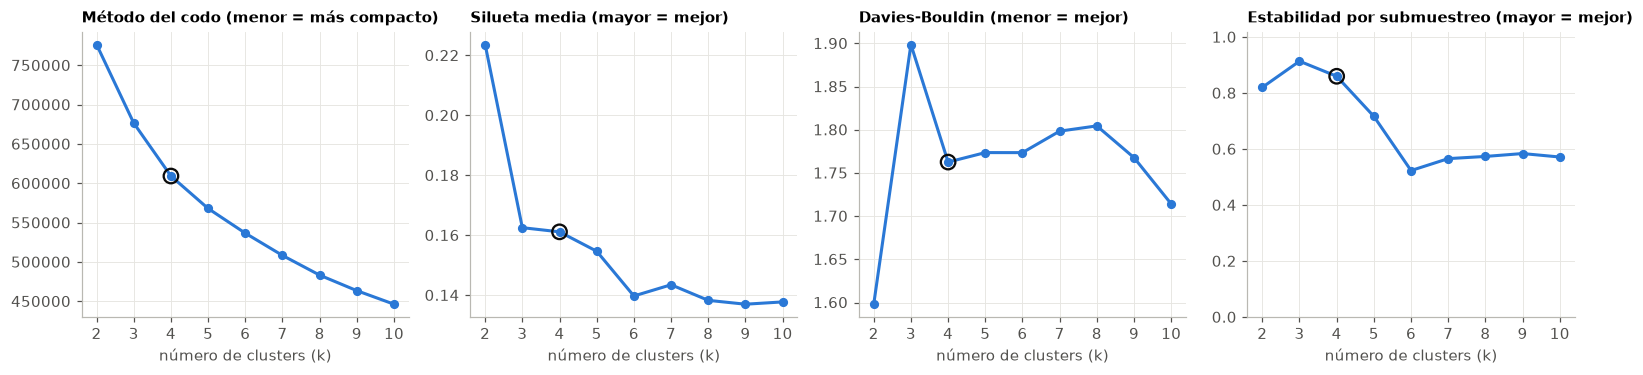

,Inercia (WCSS),Silueta,Calinski-Harabasz,Davies-Bouldin,Estabilidad (ARI medio),Estabilidad (ARI mín.),Tamaño de los clusters
k,,,,,,,
2,776526.0,0.224,121.0,1.60,0.82,0.51,"294, 118"
3,676649.0,0.163,99.4,1.90,0.91,0.35,"170, 152, 90"
4,609362.0,0.161,88.4,1.76,0.86,0.59,"126, 108, 104, 74"
5,568117.0,0.155,78.4,1.77,0.72,0.43,"122, 98, 68, 63, 61"
6,536738.0,0.140,70.9,1.77,0.52,0.31,"83, 76, 76, 75, 74, 28"
7,508454.0,0.144,66.0,1.80,0.57,0.37,"84, 73, 64, 64, 60, 44, 23"
8,483411.0,0.138,62.3,1.80,0.57,0.37,"67, 64, 59, 57, 48, 47, 46, 24"
9,463672.0,0.137,58.9,1.77,0.58,0.38,"59, 57, 55, 48, 46, 45, 41, 37, 24"
10,446468.0,0.138,55.9,1.71,0.57,0.38,"60, 50, 49, 49, 48, 39, 34, 31, 29, 23"


In [24]:
Xc = P.values                                   # 412 tumores x 10 componentes
ks = list(range(2, 11))
rng = np.random.default_rng(SEED)
modelos_km, filas = {}, []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Xc)
    modelos_km[k] = km
    # Estabilidad: se re-agrupa 50 veces un 80 % de los tumores y se compara con la partición completa
    aris = []
    for b in range(50):
        idx = rng.choice(len(Xc), int(0.8 * len(Xc)), replace=False)
        sub = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Xc[idx])
        aris.append(adjusted_rand_score(km.labels_[idx], sub.labels_))
    filas.append({"k": k, "Inercia (WCSS)": km.inertia_,
                  "Silueta": silhouette_score(Xc, km.labels_),
                  "Calinski-Harabasz": calinski_harabasz_score(Xc, km.labels_),
                  "Davies-Bouldin": davies_bouldin_score(Xc, km.labels_),
                  "Estabilidad (ARI medio)": np.mean(aris), "Estabilidad (ARI mín.)": np.min(aris),
                  "Tamaño de los clusters": ", ".join(map(str, sorted(np.bincount(km.labels_), reverse=True)))})
sel_k = pd.DataFrame(filas).set_index("k")

K = 4
fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.5))
paneles = [("Inercia (WCSS)", "Método del codo (menor = más compacto)"), ("Silueta", "Silueta media (mayor = mejor)"),
           ("Davies-Bouldin", "Davies-Bouldin (menor = mejor)"), ("Estabilidad (ARI medio)", "Estabilidad por submuestreo (mayor = mejor)")]
for ax, (col, titulo) in zip(axes, paneles):
    ax.plot(sel_k.index, sel_k[col], color=AZUL, lw=2, marker="o", ms=5)
    ax.scatter([K], [sel_k.loc[K, col]], s=90, facecolors="none", edgecolors=TINTA, linewidths=1.5, zorder=3)
    ax.set_xlabel("número de clusters (k)"); ax.set_title(titulo, fontsize=9.5); ax.set_xticks(ks)
axes[3].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

display(sel_k.round({"Inercia (WCSS)": 0, "Silueta": 3, "Calinski-Harabasz": 1, "Davies-Bouldin": 2,
                     "Estabilidad (ARI medio)": 2, "Estabilidad (ARI mín.)": 2}))

### 6.2 Justificación de k = 4

Los criterios no apuntan todos al mismo número:

- **Codo:** la inercia baja de forma suave, sin un quiebre claro. No decide.
- **Silueta:** el máximo está en *k* = 2 (0.224). Para *k* = 3 y *k* = 4 es prácticamente igual (0.163 y 0.161) y desde *k* = 6 cae a 0.14.
- **Davies-Bouldin:** el mejor valor es *k* = 2 (1.60); *k* = 3 es el peor (1.90) y *k* = 4 mejora a 1.76.
- **Estabilidad:** es alta para *k* = 3 (0.91) y *k* = 4 (0.86), baja a 0.72 en *k* = 5 y se desploma a 0.5–0.6 desde *k* = 6.

**Se elige *k* = 4** por tres razones:

1. ***k* = 2 es la partición estadísticamente más limpia, pero es demasiado gruesa.** Solo separa a los 118 tumores con más estroma de los 294 restantes, es decir, corta PC1 en dos. No sirve para explorar subgrupos y además su estabilidad (0.82) es menor que la de 3 o 4 grupos.
2. ***k* = 4 es el mayor número de grupos que sigue siendo reproducible.** A partir de *k* = 5 las particiones cambian mucho al submuestrear, señal de que se está dividiendo ruido.
3. **Frente a *k* = 3, añade un grupo sin perder calidad:** la silueta es casi idéntica, Davies-Bouldin mejora, y los cuatro grupos ocupan regiones distintas del plano PC1–PC2 (figura siguiente).

Dos advertencias. Primera: una silueta de 0.16 es baja en términos absolutos; los clusters son **regiones de un continuo**, no islas, lo que es coherente con lo visto en el PCA. Segunda: *k* = 3 también sería defendible. Las clasificaciones publicadas de cáncer gástrico tienen cuatro subtipos, pero ese dato **no** se usó para decidir, porque habría sido ajustar el análisis al resultado esperado.

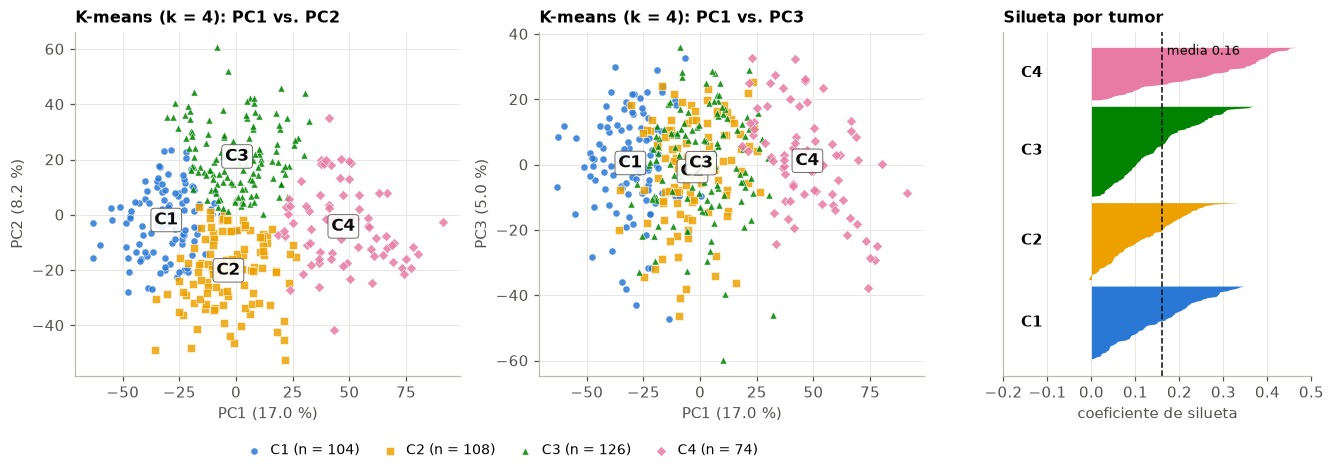

,n,% de la cohorte,Silueta media,% con silueta < 0,PC1,PC2,PC3,PC4,PC5
C1,104,25.2,0.151,1.0,-30.8,-1.8,0.5,5.7,-6.9
C2,108,26.2,0.118,6.5,-3.4,-20.1,-1.9,-6.1,5.6
C3,126,30.6,0.150,0.0,0.5,21.2,0.5,-2.4,3.5
C4,74,18.0,0.258,0.0,47.3,-4.2,1.2,5.1,-4.5


In [25]:
# Modelo final de K-means. Los clusters se renumeran de menor a mayor valor medio de PC1
# para que la numeración no dependa de la inicialización aleatoria.
km = modelos_km[K]
orden = np.argsort([P["PC1"].values[km.labels_ == c].mean() for c in range(K)])
renum = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
lab_km = np.array([renum[c] for c in km.labels_])
CL = [f"C{i + 1}" for i in range(K)]
meta["Cluster"] = pd.Categorical([CL[i] for i in lab_km], categories=CL)
sil_km = silhouette_samples(Xc, lab_km)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.8]})
fig.subplots_adjust(wspace=0.22, bottom=0.2)
for ax, (a, b) in zip(axes[:2], [("PC1", "PC2"), ("PC1", "PC3")]):
    for i, c in enumerate(CL):
        m = lab_km == i
        ax.scatter(P.loc[m, a], P.loc[m, b], s=22, color=COL_CLUSTER[i], marker=MARCADORES[i], alpha=0.85,
                   edgecolors="white", linewidths=0.4, label=f"{c} (n = {m.sum()})")
        ax.text(P.loc[m, a].mean(), P.loc[m, b].mean(), c, fontsize=11, fontweight="bold", ha="center", va="center",
                color=TINTA, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=TINTA2, lw=0.6, alpha=0.9))
    ia, ib = int(a[2:]) - 1, int(b[2:]) - 1
    ax.set_xlabel(f"{a} ({100 * evr[ia]:.1f} %)"); ax.set_ylabel(f"{b} ({100 * evr[ib]:.1f} %)")
    ax.set_title(f"K-means (k = {K}): {a} vs. {b}")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -0.16), ncol=4, handletextpad=0.2, columnspacing=1.2)

# Gráfico de silueta
y0 = 0
for i, c in enumerate(CL):
    s = np.sort(sil_km[lab_km == i])
    axes[2].fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, color=COL_CLUSTER[i], lw=0)
    axes[2].text(-0.16, y0 + len(s) / 2, c, va="center", fontweight="bold")
    y0 += len(s) + 8
axes[2].axvline(sil_km.mean(), color=TINTA, ls="--", lw=1)
axes[2].text(sil_km.mean() + 0.01, y0 - 4, f"media {sil_km.mean():.2f}", fontsize=8.5, va="top")
axes[2].set_yticks([]); axes[2].set_xlabel("coeficiente de silueta"); axes[2].set_xlim(-0.2, 0.5)
axes[2].set_title("Silueta por tumor"); axes[2].grid(axis="y", visible=False)
plt.show()

tab_km = pd.DataFrame({"n": np.bincount(lab_km), "% de la cohorte": (100 * np.bincount(lab_km) / len(lab_km)).round(1),
                       "Silueta media": [sil_km[lab_km == i].mean().round(3) for i in range(K)],
                       "% con silueta < 0": [round(100 * (sil_km[lab_km == i] < 0).mean(), 1) for i in range(K)]}, index=CL)
tab_km = pd.concat([tab_km, P.iloc[:, :5].groupby(lab_km).mean().round(1).set_axis(CL)], axis=1)
display(tab_km)

**Lectura de la partición K-means:** los cuatro clusters tienen tamaños equilibrados (74 a 126 tumores) y se reparten el plano de los dos primeros componentes: **C1** en el extremo negativo de PC1, **C4** en el positivo, y **C2** y **C3** en la zona central, separados entre sí por PC2 (C3 arriba, C2 abajo). Los clusters se numeran de menor a mayor PC1.

**C4** es el grupo mejor definido (silueta 0.26, ningún tumor con silueta negativa). **C2** es el más difuso (0.12, con 6.5 % de sus tumores más cerca de otro cluster que del propio).

### 6.3 Clustering jerárquico

El resultado del clustering jerárquico depende del **criterio de enlace**, es decir, de cómo se mide la distancia entre dos grupos al fusionarlos. Primero se comparan los cuatro enlaces habituales cortando el árbol en 4 grupos.

In [26]:
# Clustering jerárquico aglomerativo sobre el mismo espacio (10 PCs, distancia euclidiana)
enlaces = {m: hierarchy.linkage(Xc, method=m, metric="euclidean") for m in ["single", "complete", "average", "ward"]}
d_orig = pdist(Xc)
comp = []
for m, L in enlaces.items():
    lab = hierarchy.fcluster(L, K, criterion="maxclust")
    comp.append({"Enlace": m, "Correlación cofenética": round(hierarchy.cophenet(L, d_orig)[0], 2),
                 f"Tamaños con k = {K}": ", ".join(map(str, sorted(np.bincount(lab)[1:], reverse=True))),
                 "Silueta": round(silhouette_score(Xc, lab), 3)})
display(pd.DataFrame(comp).set_index("Enlace"))

,Correlación cofenética,Tamaños con k = 4,Silueta
Enlace,,,
single,0.36,"409, 1, 1, 1",0.182
complete,0.44,"152, 126, 114, 20",0.109
average,0.63,"389, 20, 2, 1",0.199
ward,0.43,"169, 157, 65, 21",0.119


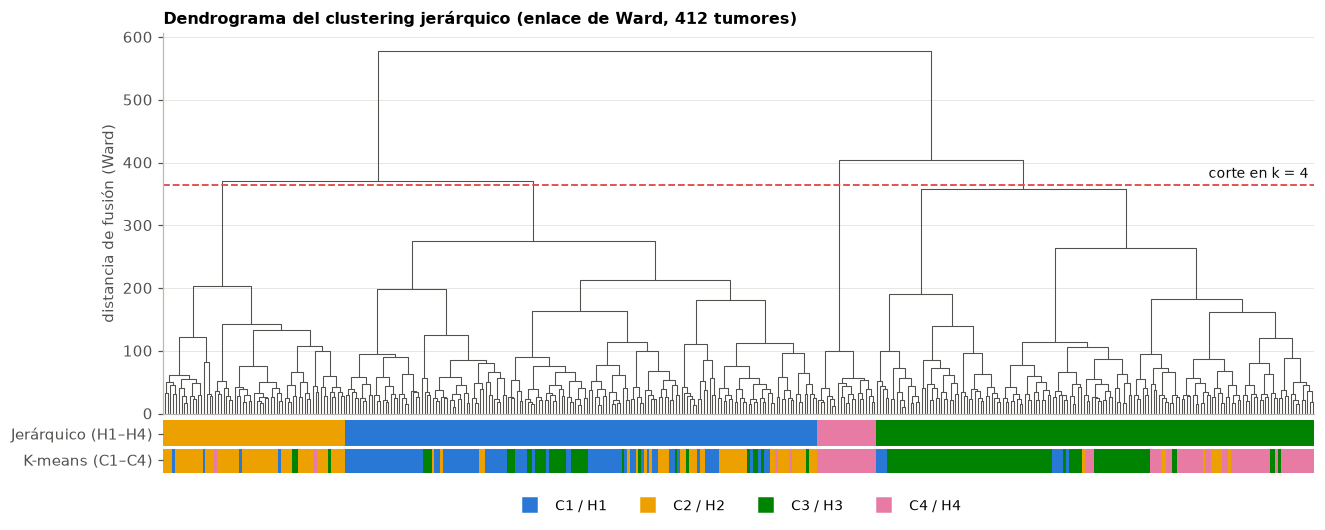

Alturas de las últimas fusiones (de la raíz hacia abajo): 578, 404, 372, 358, 275, 264, 213


,Silueta (Ward),Silueta (K-means),ARI Ward vs. K-means,Tamaños (Ward)
k,,,,
2,0.155,0.224,0.325,"234, 178"
3,0.131,0.163,0.342,"234, 157, 21"
4,0.119,0.161,0.290,"169, 157, 65, 21"
5,0.126,0.155,0.347,"169, 112, 65, 45, 21"
6,0.111,0.140,0.317,"112, 111, 65, 58, 45, 21"
7,0.100,0.144,0.408,"111, 65, 65, 58, 47, 45, 21"
8,0.097,0.138,0.453,"65, 65, 62, 58, 49, 47, 45, 21"
9,0.104,0.137,0.467,"65, 62, 58, 49, 47, 47, 45, 21, 18"
10,0.104,0.138,0.466,"65, 62, 49, 47, 47, 45, 31, 27, 21, 18"


In [27]:
L_ward = enlaces["ward"]
filas = []
for k in ks:
    lab = hierarchy.fcluster(L_ward, k, criterion="maxclust")
    filas.append({"k": k, "Silueta (Ward)": silhouette_score(Xc, lab), "Silueta (K-means)": sel_k.loc[k, "Silueta"],
                  "ARI Ward vs. K-means": adjusted_rand_score(lab, modelos_km[k].labels_),
                  "Tamaños (Ward)": ", ".join(map(str, sorted(np.bincount(lab)[1:], reverse=True)))})
sel_h = pd.DataFrame(filas).set_index("k")

# Partición jerárquica con k = 4, renombrada (H1..H4) para que cada grupo coincida con su cluster K-means más parecido
lab_h_bruto = hierarchy.fcluster(L_ward, K, criterion="maxclust") - 1
conting = pd.crosstab(lab_h_bruto, lab_km).values
fil, col = linear_sum_assignment(-conting)
mapa = dict(zip(fil, col))
lab_h = np.array([mapa[c] for c in lab_h_bruto])
HL = [f"H{i + 1}" for i in range(K)]
meta["Cluster_jerarquico"] = pd.Categorical([HL[i] for i in lab_h], categories=HL)

# Dendrograma con dos bandas de color: partición jerárquica y partición K-means
fig = plt.figure(figsize=(13.5, 5.2))
gs = fig.add_gridspec(2, 1, height_ratios=[5, 0.7], hspace=0.03)
ax = fig.add_subplot(gs[0])
hierarchy.set_link_color_palette([TINTA2])
dn = hierarchy.dendrogram(L_ward, no_labels=True, color_threshold=0, above_threshold_color=TINTA2, ax=ax)
alturas = np.sort(L_ward[:, 2])
corte = (alturas[-K] + alturas[-(K - 1)]) / 2
ax.axhline(corte, color=ROJO, ls="--", lw=1.2)
ax.text(ax.get_xlim()[1] * 0.995, corte * 1.03, f"corte en k = {K}", color=TINTA, ha="right", fontsize=9)
ax.set_ylabel("distancia de fusión (Ward)"); ax.set_title("Dendrograma del clustering jerárquico (enlace de Ward, 412 tumores)")
ax.grid(axis="x", visible=False); ax.set_xticks([])
for coll in ax.collections:
    coll.set_linewidth(0.7)

hojas = dn["leaves"]
ax2 = fig.add_subplot(gs[1])
ax2.imshow(np.vstack([lab_h[hojas], lab_km[hojas]]), aspect="auto", cmap=ListedColormap(COL_CLUSTER), vmin=0, vmax=K - 1,
           interpolation="nearest")
ax2.set_yticks([0, 1]); ax2.set_yticklabels(["Jerárquico (H1–H4)", "K-means (C1–C4)"]); ax2.set_xticks([]); ax2.grid(False)
ax2.axhline(0.5, color="white", lw=2)
for s in ax2.spines.values():
    s.set_visible(False)
ax2.legend(handles=[Line2D([], [], marker="s", ls="", color=COL_CLUSTER[i], ms=9, label=f"C{i + 1} / H{i + 1}") for i in range(K)],
           loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=K)
plt.show()

print("Alturas de las últimas fusiones (de la raíz hacia abajo):", ", ".join(f"{h:.0f}" for h in alturas[::-1][:7]))
display(sel_h.round(3))

**Lectura:**

- **El enlace importa mucho.** Los enlaces simple y promedio sufren *encadenamiento*: producen un grupo gigante (409 y 389 tumores) y grupos residuales de entre 1 y 20 tumores. Su silueta parece más alta, pero es un artefacto de aislar unos pocos puntos extremos; esas particiones no sirven para describir subgrupos. El enlace promedio tiene la mejor correlación cofenética (0.63), es decir, su árbol es el que mejor respeta las distancias originales, lo que confirma que los datos se parecen más a una nube continua con algunos puntos periféricos que a grupos compactos.
- **Se elige el enlace de Ward**, que en cada paso fusiona los dos grupos que menos aumentan la varianza interna. Produce grupos de tamaño utilizable (169, 157, 65 y 21) y optimiza el mismo criterio que K-means, lo que hace comparable el resultado. Su correlación cofenética es moderada (0.43).
- **El dendrograma no señala un número de grupos evidente.** La mayor brecha está entre la última fusión (altura 578) y la anterior (404), lo que apoya *k* = 2, igual que la silueta. Las fusiones que definen 3, 4 y 5 grupos ocurren a alturas parecidas (404, 372 y 358) y después hay otro salto hasta 275. Se corta en *k* = 4 para poder comparar con K-means.
- Las dos bandas de color bajo el árbol ya adelantan el resultado de la comparación: los colores coinciden en buena parte, pero el grupo rosa del jerárquico es mucho más pequeño que el de K-means.

### 6.4 Comparación entre K-means y clustering jerárquico

Para comparar, los grupos jerárquicos se renombran H1–H4 de modo que cada uno corresponda al cluster de K-means con el que más tumores comparte.

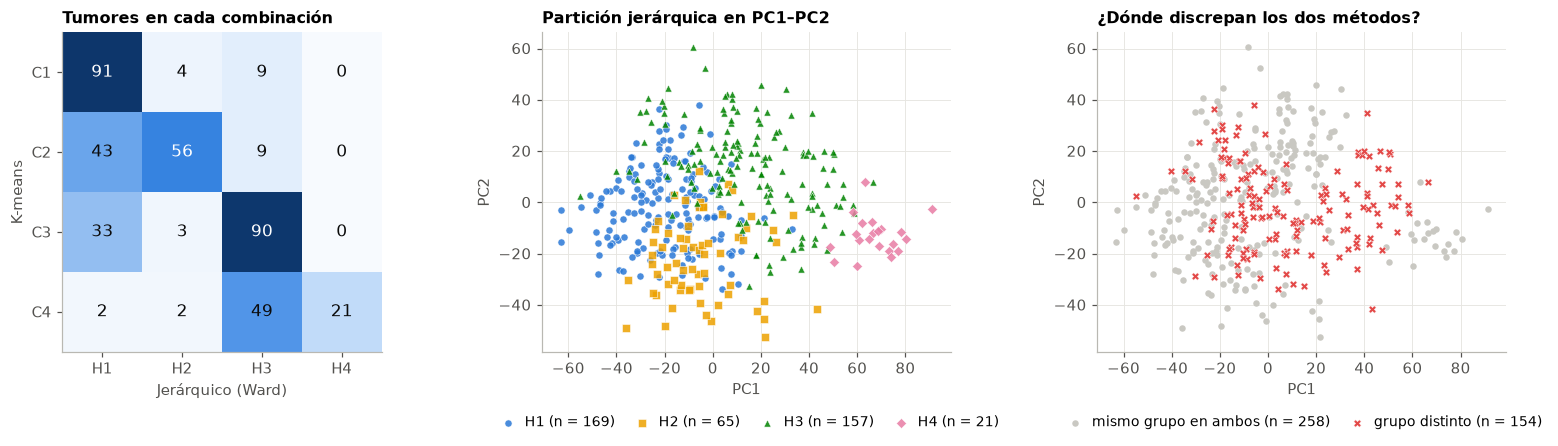

Índice de Rand ajustado (ARI): 0.29   ·   Información mutua ajustada (AMI): 0.36
Tumores asignados al grupo equivalente por ambos métodos: 258 de 412 (63 %)
Silueta media (K-means) de los tumores concordantes: 0.181   ·   de los discordantes: 0.128
Silueta global: K-means 0.161   ·   Ward 0.119
Concordancia por cluster de K-means (% de sus tumores que caen en el grupo jerárquico equivalente): C1: 88 %, C2: 52 %, C3: 71 %, C4: 28 %


In [28]:
tabla_cruzada = pd.crosstab(meta["Cluster"], meta["Cluster_jerarquico"])
ari = adjusted_rand_score(lab_km, lab_h); ami = adjusted_mutual_info_score(lab_km, lab_h)
coincide = lab_km == lab_h

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), gridspec_kw={"width_ratios": [0.85, 1, 1]})
ax = axes[0]
im = ax.imshow(tabla_cruzada.values, cmap=CMAP_SEQ, vmin=0)
for i in range(K):
    for j in range(K):
        v = tabla_cruzada.values[i, j]
        ax.text(j, i, str(v), ha="center", va="center", fontsize=11, color="white" if v > tabla_cruzada.values.max() * 0.55 else TINTA)
ax.set_xticks(range(K)); ax.set_xticklabels(HL); ax.set_yticks(range(K)); ax.set_yticklabels(CL)
ax.set_xlabel("Jerárquico (Ward)"); ax.set_ylabel("K-means"); ax.grid(False)
ax.set_title("Tumores en cada combinación")

ax = axes[1]
for i, h in enumerate(HL):
    m = lab_h == i
    ax.scatter(P.loc[m, "PC1"], P.loc[m, "PC2"], s=22, color=COL_CLUSTER[i], marker=MARCADORES[i], alpha=0.85,
               edgecolors="white", linewidths=0.4, label=f"{h} (n = {m.sum()})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Partición jerárquica en PC1–PC2")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, handletextpad=0.2, columnspacing=1.0)

ax = axes[2]
ax.scatter(P.loc[coincide, "PC1"], P.loc[coincide, "PC2"], s=18, color="#c9c8c2", linewidths=0, label=f"mismo grupo en ambos (n = {coincide.sum()})")
ax.scatter(P.loc[~coincide, "PC1"], P.loc[~coincide, "PC2"], s=24, color=ROJO, marker="X", edgecolors="white", linewidths=0.3,
           label=f"grupo distinto (n = {(~coincide).sum()})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("¿Dónde discrepan los dos métodos?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, handletextpad=0.2, columnspacing=1.0)
plt.tight_layout(); plt.show()

print(f"Índice de Rand ajustado (ARI): {ari:.2f}   ·   Información mutua ajustada (AMI): {ami:.2f}")
print(f"Tumores asignados al grupo equivalente por ambos métodos: {coincide.sum()} de {len(coincide)} ({100 * coincide.mean():.0f} %)")
print(f"Silueta media (K-means) de los tumores concordantes: {sil_km[coincide].mean():.3f}   ·   de los discordantes: {sil_km[~coincide].mean():.3f}")
print(f"Silueta global: K-means {sil_km.mean():.3f}   ·   Ward {silhouette_score(Xc, lab_h):.3f}")
print("Concordancia por cluster de K-means (% de sus tumores que caen en el grupo jerárquico equivalente):",
      ", ".join(f"{c}: {100 * coincide[lab_km == i].mean():.0f} %" for i, c in enumerate(CL)))

In [29]:
# Análisis de sensibilidad: ¿cuánto cambia la partición K-means (k = 4) si se modifican las decisiones previas?
def particion(n_genes=N_GENES, n_pcs=N_PCS, muestras=None):
    idx = tumores if muestras is None else muestras
    g = Xf.loc[:, idx].var(axis=1).sort_values(ascending=False).index[:n_genes]
    z = Xf.loc[g, idx].T
    z = (z - z.mean()) / z.std()
    # Rellenamos los valores faltantes de z con 0 (la media tras estandarizar) para evitar el error en el PCA
    z_imputed = z.fillna(0)
    s = PCA(n_components=n_pcs, svd_solver="full").fit_transform(z_imputed)
    return KMeans(n_clusters=K, n_init=50, random_state=SEED).fit_predict(s)

ref = pd.Series(lab_km, index=tumores)
sin_atipicos = [s for s in tumores if s not in set(atip_pca.index) | set(qc.index[atipico_qc.sum(axis=1) >= 2])]
variantes = [("2,000 genes más variables", dict(n_genes=2000)), ("10,000 genes más variables", dict(n_genes=10000)),
             ("5 componentes", dict(n_pcs=5)), ("8 componentes", dict(n_pcs=8)),
             ("15 componentes", dict(n_pcs=15)), ("20 componentes", dict(n_pcs=20)),
             (f"sin los {len(tumores) - len(sin_atipicos)} tumores atípicos", dict(muestras=sin_atipicos))]
filas = []
for nombre, kw in variantes:
    lab = particion(**kw)
    idx = kw.get("muestras", tumores)
    filas.append({"Variante (el resto igual que el análisis principal)": nombre,
                  "ARI vs. partición principal": round(adjusted_rand_score(ref[idx], lab), 2),
                  "Tamaños": ", ".join(map(str, sorted(np.bincount(lab), reverse=True)))})
display(pd.DataFrame(filas).set_index("Variante (el resto igual que el análisis principal)"))

,ARI vs. partición principal,Tamaños
Variante (el resto igual que el análisis principal),,
"2,000 genes más variables",0.64,"134, 104, 101, 73"
"10,000 genes más variables",0.52,"121, 117, 106, 68"
5 componentes,0.85,"132, 109, 95, 76"
8 componentes,0.92,"130, 106, 101, 75"
15 componentes,0.91,"131, 104, 100, 77"
20 componentes,0.98,"125, 111, 102, 74"
sin los 3 tumores atípicos,0.92,"131, 103, 99, 76"


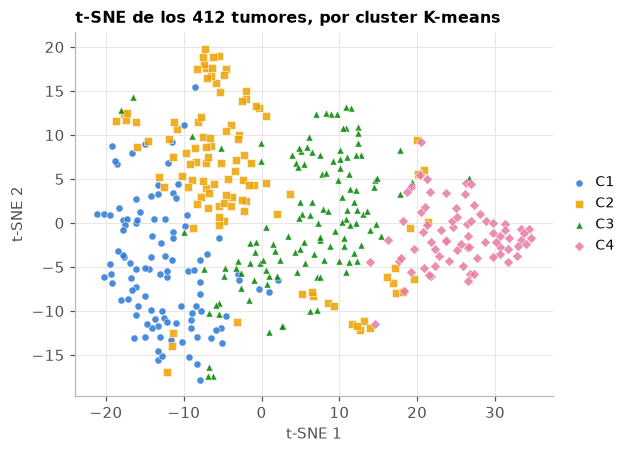

In [30]:
# Vista complementaria no lineal (t-SNE sobre los 10 PCs); solo para visualizar, no para agrupar
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Xc)
fig, ax = plt.subplots(figsize=(5.6, 4.3))
for i, c in enumerate(CL):
    m = lab_km == i
    ax.scatter(tsne[m, 0], tsne[m, 1], s=22, color=COL_CLUSTER[i], marker=MARCADORES[i], alpha=0.85,
               edgecolors="white", linewidths=0.4, label=c)
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.set_title("t-SNE de los 412 tumores, por cluster K-means")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handletextpad=0.2)
plt.show()

### 6.5 Similitudes, diferencias y posibles explicaciones

**Similitudes.** Los dos métodos reconocen las mismas regiones del espacio:

- H1 contiene a 91 de los 104 tumores de C1 (88 %).
- H3 contiene a 90 de los 126 de C3 (71 %).
- H2 está formado casi solo por tumores de C2 (56 de 65).
- H4 está formado íntegramente por tumores de C4 (21 de 21).

Los ejes que organizan ambas particiones son los mismos: PC1 (estroma) y PC2 (infiltración inmune).

**Diferencias.** La concordancia global es **modesta**: ARI = 0.29, AMI = 0.36, y solo el 63 % de los tumores (258 de 412) cae en el grupo equivalente. Las discrepancias principales:

- **El grupo estromal.** Ward aísla solo el núcleo más extremo (H4, 21 tumores) y reparte los otros 49 tumores de C4 dentro de H3, junto con los tumores inmunes. K-means forma un grupo estromal más amplio (74).
- **El grupo H1 es mucho mayor que C1** (169 frente a 104): absorbe 43 tumores de C2 y 33 de C3.

**Posibles explicaciones:**

1. **Los datos son un continuo.** Si hubiera grupos separados por zonas vacías, cualquier método razonable los encontraría. Como no las hay, cada algoritmo traza las fronteras en un lugar distinto. La evidencia es que los tumores discordantes tienen una silueta menor (0.128) que los concordantes (0.181) y se concentran en la zona central de la nube y en la transición hacia C4 (panel derecho), mientras que los extremos se asignan igual con ambos métodos.
2. **Los algoritmos optimizan de forma distinta.** Ward es voraz: una fusión hecha al principio no se puede deshacer, así que una decisión temprana condiciona todo el árbol. K-means reasigna los tumores en cada iteración hasta minimizar la inercia global para ese *k*. Por eso K-means logra grupos más compactos (silueta 0.161 frente a 0.119) aunque ambos persigan el mismo criterio.
3. **Ward tiende a separar primero lo más extremo y compacto** (el núcleo estromal), mientras que K-means prefiere particiones de tamaños más parecidos.

**Análisis de sensibilidad de la partición K-means:**

- **Número de componentes:** casi no influye (ARI de 0.85 a 0.98 al usar 5, 8, 15 o 20 componentes).
- **Tumores atípicos:** no influyen (ARI = 0.92 al quitar los 3 marcados).
- **Número de genes:** influye más (ARI = 0.64 con 2 000 genes y 0.52 con 10 000). Los grupos conservan tamaños parecidos, pero una parte de los tumores cambia de grupo. La selección de genes es la decisión de la que más dependen los resultados.

El t-SNE, una proyección no lineal usada solo para visualizar, cuenta la misma historia: los cuatro clusters ocupan zonas contiguas de una misma nube, sin huecos entre ellos, y C4 es el más apartado.

### 6.6 Modelo seleccionado para la interpretación

Para las secciones siguientes se usa **K-means con *k* = 4**, por tres motivos:

- tiene mejor silueta que Ward para el mismo número de grupos (0.161 frente a 0.119);
- su estabilidad se midió directamente por submuestreo (ARI medio 0.86);
- sus grupos tienen tamaños equilibrados (74–126), lo que da potencia a las comparaciones estadísticas; el grupo de 21 tumores de Ward dejaría muchas tablas con celdas casi vacías.

La baja concordancia entre métodos es en sí misma un resultado: los cuatro clusters deben leerse como **zonas de un espacio continuo** y no como subtipos con fronteras nítidas.

## 7. Interpretación de los clusters: análisis de genes

¿Qué genes distinguen a los cuatro clusters? Se evalúan los **18 500 genes** que pasaron los filtros de calidad (no solo los 5 000 usados para agrupar) con dos análisis:

1. **Prueba global por gen (Kruskal-Wallis):** ¿la expresión del gen difiere entre los 4 clusters? Es una prueba no paramétrica, adecuada porque la expresión no sigue una distribución normal. El tamaño del efecto se resume con eta² (proporción de la variación del gen explicada por el cluster).
2. **Cada cluster contra el resto (Mann-Whitney):** para encontrar los marcadores de cada grupo. Se reporta la diferencia de medias en escala log2 (aproximadamente el log2 del cambio en veces, *log2 fold change*) y el AUC.

Como se hacen miles de pruebas, los valores p se corrigen con el método de **Benjamini-Hochberg**, que controla la proporción de falsos descubrimientos (FDR).

> **Advertencia metodológica.** Los clusters se construyeron a partir de la expresión, así que es inevitable que muchos genes «difieran significativamente» entre ellos: es un razonamiento circular (*double dipping*). Los valores p de esta sección sirven para **ordenar y describir**, no como prueba de que los grupos existan. Lo informativo es *qué* genes aparecen y *cuánto* cambian.

In [31]:
def bh(p):
    """Corrección de Benjamini-Hochberg (FDR)."""
    p = np.asarray(p, dtype=float); n = len(p); o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1); return out

cl = meta["Cluster"]
mats = [Xf.loc[:, (cl == c).values].values for c in CL]

# (1) Prueba global: Kruskal-Wallis por gen entre los 4 clusters
H, p_kw = stats.kruskal(*mats, axis=1)
n_tot = Xf.shape[1]
genes = pd.DataFrame({"gen": simbolo.values, "H": H, "p": p_kw, "FDR": bh(p_kw),
                      "eta2": np.clip((H - K + 1) / (n_tot - K), 0, None),
                      "usado_para_agrupar": Xf.index.isin(hvg)}, index=Xf.index)
for c, m in zip(CL, mats):
    genes[f"media_{c}"] = m.mean(axis=1)

# (2) Cada cluster contra el resto: diferencia de medias en log2 (≈ log2 fold change) y Mann-Whitney
for c in CL:
    a = Xf.loc[:, (cl == c).values].values; b = Xf.loc[:, (cl != c).values].values
    U, p = stats.mannwhitneyu(a, b, axis=1, alternative="two-sided")
    genes[f"log2FC_{c}"] = a.mean(axis=1) - b.mean(axis=1)
    genes[f"AUC_{c}"] = U / (a.shape[1] * b.shape[1])
    genes[f"FDR_{c}"] = bh(p)

print(f"Genes evaluados: {len(genes):,}")
print(f"Genes con diferencias entre clusters (Kruskal-Wallis, FDR < 0.01): {(genes.FDR < 0.01).sum():,} ({100 * (genes.FDR < 0.01).mean():.0f} %)")
print(f"   · con efecto grande (eta² ≥ 0.14): {((genes.FDR < 0.01) & (genes.eta2 >= 0.14)).sum():,}")
no_usados = genes[~genes.usado_para_agrupar]
print(f"Entre los {len(no_usados):,} genes que NO se usaron para construir los clusters: "
      f"{(no_usados.FDR < 0.01).sum():,} significativos ({100 * (no_usados.FDR < 0.01).mean():.0f} %)")

resumen_de = pd.DataFrame({
    "Sobreexpresados (FDR < 0.01, log2FC ≥ 1)": {c: int(((genes[f"FDR_{c}"] < 0.01) & (genes[f"log2FC_{c}"] >= 1)).sum()) for c in CL},
    "Subexpresados (FDR < 0.01, log2FC ≤ −1)": {c: int(((genes[f"FDR_{c}"] < 0.01) & (genes[f"log2FC_{c}"] <= -1)).sum()) for c in CL}})
display(resumen_de)

Genes evaluados: 18,500
Genes con diferencias entre clusters (Kruskal-Wallis, FDR < 0.01): 15,762 (85 %)
   · con efecto grande (eta² ≥ 0.14): 5,664
Entre los 13,500 genes que NO se usaron para construir los clusters: 11,243 significativos (83 %)


,"Sobreexpresados (FDR < 0.01, log2FC ≥ 1)","Subexpresados (FDR < 0.01, log2FC ≤ −1)"
C1,40,1154
C2,302,123
C3,403,59
C4,1660,216


In [32]:
# Genes marcadores: los más sobre- y subexpresados de cada cluster frente al resto
N_TOP = 15
marcadores, filas = {}, []
for c in CL:
    sig = genes[genes[f"FDR_{c}"] < 0.01]
    arriba = sig.sort_values(f"log2FC_{c}", ascending=False).head(N_TOP)
    abajo = sig.sort_values(f"log2FC_{c}").head(N_TOP)
    marcadores[c] = arriba.index.tolist()
    filas.append({"Cluster": c, "n": int((cl == c).sum()),
                  "Más SOBREEXPRESADOS frente al resto": ", ".join(arriba.gen),
                  "Más SUBEXPRESADOS frente al resto": ", ".join(abajo.gen)})
display(pd.DataFrame(filas).set_index("Cluster"))

detalle = pd.concat([genes.loc[marcadores[c][:6], ["gen", f"log2FC_{c}", f"AUC_{c}", f"FDR_{c}"]]
                     .set_axis(["gen", "log2FC", "AUC", "FDR"], axis=1).assign(Cluster=c) for c in CL])
detalle["log2FC"] = detalle["log2FC"].round(2); detalle["AUC"] = detalle["AUC"].round(2)
detalle["FDR"] = detalle["FDR"].map(lambda v: f"{v:.1e}")
print("Detalle de los 6 primeros marcadores por cluster (AUC = probabilidad de que un tumor del cluster exprese más el gen que uno de fuera):")
display(detalle.set_index(["Cluster", "gen"]))

,n,Más SOBREEXPRESADOS frente al resto,Más SUBEXPRESADOS frente al resto
Cluster,,,
C1,104,"REG4, CA9, PPP1R1B, PHGR1, MUC17, GPA33, AGR2, AKR7A3, TFF3, CDX1, S100A14, FGFBP1, CDH17, FUT3, AKR1B10","DES, SFRP4, HSPB6, SFRP2, CCL19, THBS4, FBLN1, APOD, PTGIS, CHRDL2, MYH11, PRELP, OGN, CNN1, CCL21"
C2,108,"PCSK1N, MAGEA3, CLDN6, MAGEA6, CSAG1, NOTUM, HOXC12, MAGEA12, PRAME, APOA1, IGF2BP1, HOXC13, H19, WFDC2, KRT23","PIGR, IGHV4-59, IGHM, IGHV3-49, IGLV5-45, JCHAIN, IGLV6-57, IGLV2-18, IGKV1-27, CXCL13, GZMA, IGLV7-43, IGLV8-61, IGHV3-43, CTSE"
C3,126,"IGHV4-59, IGKV1-17, IGLV5-45, IGHV3-33, IGHGP, IGLV3-1, IGHV3-7, IGLV3-10, IGHV3-48, IGHM, IGHV3-21, IGHV3-15, IGKV1-16, IGLV6-57, IGKV3D-20","CLDN3, PCSK1N, H19, SPINK4, TM4SF4, CKB, WFDC2, CRABP2, MAGEA3, CDH17, WNK2, BMP7, SYT7, NKD2, CDX1"
C4,74,"DES, MYH11, HSPB6, ACTG2, CNN1, C7, OGN, THBS4, SYNPO2, SYNM, FLNC, HSPB7, SFRP1, ECRG4, LMOD1","MMP12, CCL20, LCN2, S100A7, CEACAM7, RHOV, UBE2C, PCSK9, PI3, MYBL2, CDC6, TOP2A, CDH1, GRB7, TPX2"


Detalle de los 6 primeros marcadores por cluster (AUC = probabilidad de que un tumor del cluster exprese más el gen que uno de fuera):


log2FC   AUC      FDR
Cluster gen                            
C1      REG4        1.73  0.65  2.3e-05
        CA9         1.64  0.70  1.4e-08
        PPP1R1B     1.56  0.69  2.1e-08
        PHGR1       1.56  0.65  2.9e-05
        MUC17       1.51  0.66  8.1e-06
        GPA33       1.48  0.68  4.3e-07
C2      PCSK1N      2.93  0.78  7.3e-16
        MAGEA3      2.72  0.74  1.9e-12
        CLDN6       2.67  0.78  2.5e-15
        MAGEA6      2.47  0.74  1.8e-12
        CSAG1       2.43  0.72  4.7e-10
        NOTUM       2.39  0.76  3.3e-14
C3      IGHV4-59    2.53  0.82  2.4e-22
        IGKV1-17    2.50  0.79  1.8e-19
        IGLV5-45    2.48  0.81  8.1e-22
        IGHV3-33    2.46  0.78  2.9e-18
        IGHGP       2.46  0.75  2.0e-14
        IGLV3-1     2.45  0.81  3.6e-22
C4      DES         5.28  0.89  5.4e-24
        MYH11       4.84  0.94  1.4e-30
        HSPB6       4.78  0.96  1.3e-33
        ACTG2       4.58  0.90  3.4e-26
        CNN1        4.49  0.93  3.4e-29
        C7          4.42  0.95  3.6e-32

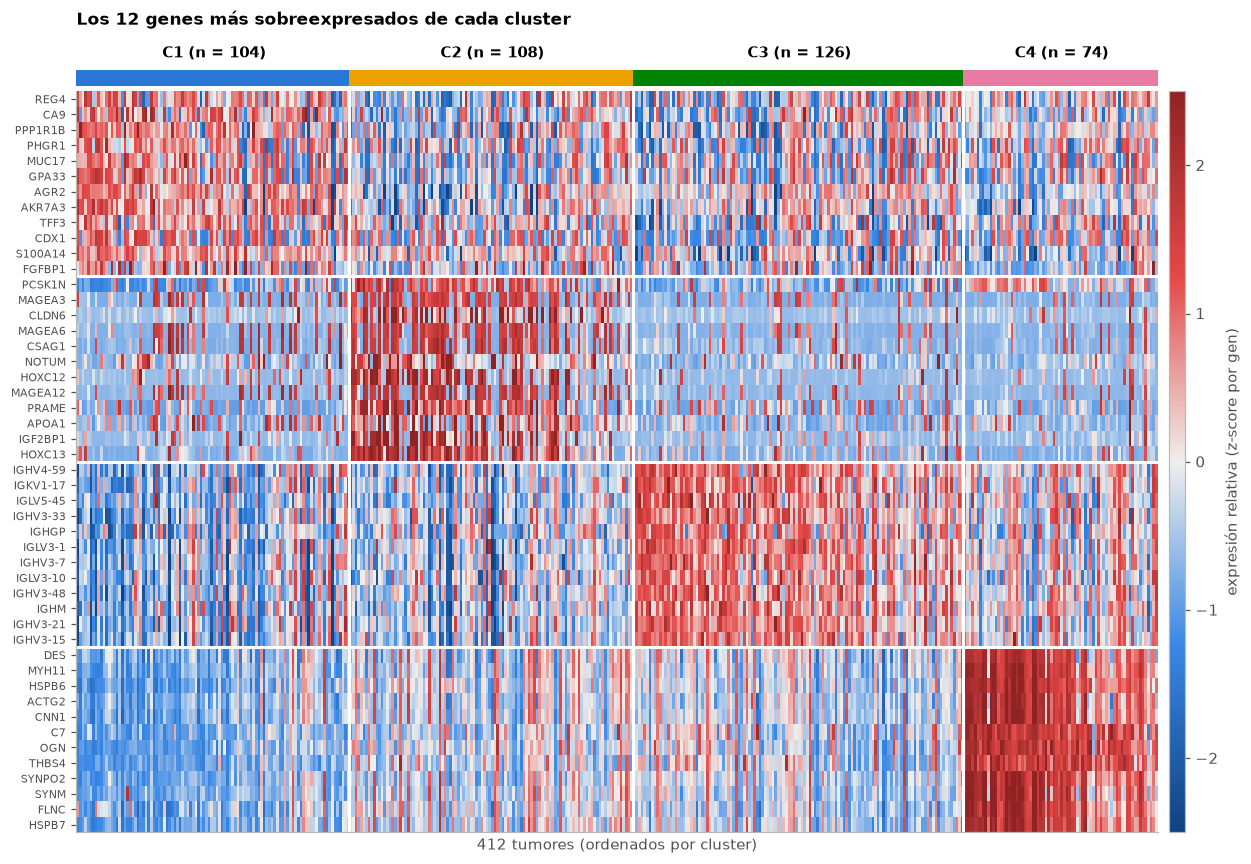

In [33]:
# Mapa de calor de los marcadores (z-score por gen), tumores ordenados por cluster
orden_m = np.concatenate([np.where(lab_km == i)[0][np.argsort(-sil_km[lab_km == i])] for i in range(K)])
genes_hm = [g for c in CL for g in marcadores[c][:12]]
Zhm = Xf.loc[genes_hm].iloc[:, orden_m]
Zhm = Zhm.sub(Zhm.mean(axis=1), axis=0).div(Zhm.std(axis=1), axis=0).clip(-2.5, 2.5)

fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[0.25, 12], width_ratios=[40, 0.6], hspace=0.015, wspace=0.02)
axb = fig.add_subplot(gs[0, 0])
axb.imshow(lab_km[orden_m][None, :], aspect="auto", cmap=ListedColormap(COL_CLUSTER), vmin=0, vmax=K - 1, interpolation="nearest")
limites = np.cumsum([0] + [(lab_km == i).sum() for i in range(K)])
for i, c in enumerate(CL):
    axb.text((limites[i] + limites[i + 1]) / 2, -1.1, f"{c} (n = {limites[i + 1] - limites[i]})", ha="center", va="bottom", fontweight="bold")
axb.set_xticks([]); axb.set_yticks([]); axb.grid(False)
for s in axb.spines.values():
    s.set_visible(False)
axh = fig.add_subplot(gs[1, 0])
im = axh.imshow(Zhm.values, aspect="auto", cmap=CMAP_DIV, vmin=-2.5, vmax=2.5, interpolation="nearest")
axh.set_yticks(range(len(genes_hm))); axh.set_yticklabels(simbolo[genes_hm].values, fontsize=7.5)
axh.set_xticks([]); axh.grid(False); axh.set_xlabel("412 tumores (ordenados por cluster)")
for x in limites[1:-1]:
    axh.axvline(x - 0.5, color="white", lw=2)
for y in range(12, len(genes_hm), 12):
    axh.axhline(y - 0.5, color="white", lw=2)
cax = fig.add_subplot(gs[1, 1])
fig.colorbar(im, cax=cax, label="expresión relativa (z-score por gen)")
fig.suptitle("Los 12 genes más sobreexpresados de cada cluster", x=0.125, y=0.94, ha="left", fontweight="bold", fontsize=11)
plt.show()

**Lectura:**

- **15 762 de los 18 500 genes (85 %) difieren entre clusters** con FDR < 0.01. Por la circularidad ya mencionada este porcentaje no demuestra nada por sí solo. Es más informativo que el 83 % de los 13 500 genes que **no** se usaron para agrupar también difiera: las diferencias atraviesan todo el transcriptoma y no se limitan a los genes seleccionados (aunque tampoco es una validación independiente, porque esos genes están correlacionados con los usados).
- **5 664 genes tienen un efecto grande** (eta² ≥ 0.14: el cluster explica al menos el 14 % de su variación).
- **La asimetría entre clusters es marcada.** C4 tiene 1 660 genes sobreexpresados frente al resto y C1 solo 40, pero C1 tiene 1 154 subexpresados. Es decir, C1 se define sobre todo por lo que **le falta** (los genes de estroma y de células inmunes) y C4 por lo que **le sobra**.
- **Los marcadores son coherentes dentro de cada grupo:**
  - **C1:** *REG4*, *CDX1*, *CDH17*, *TFF3*, *MUC17*, *GPA33*, *AGR2*: genes del epitelio intestinal.
  - **C2:** *MAGEA3*, *MAGEA6*, *MAGEA12*, *CSAG1*, *PRAME* (antígenos cáncer-testículo), junto con *CLDN6*, *IGF2BP1*, *H19* y genes *HOXC* (programas embrionarios).
  - **C3:** casi exclusivamente genes de inmunoglobulinas (*IGHV*, *IGKV*, *IGLV*, *IGHM*), producidos por células plasmáticas.
  - **C4:** *DES*, *MYH11*, *ACTG2*, *CNN1*, *SYNPO2*: genes de músculo liso, con los cambios más grandes del análisis (log2FC de 4.4 a 5.3, es decir, entre 20 y 40 veces más expresión; AUC 0.89–0.96).
- El mapa de calor muestra bloques nítidos para C2, C3 y C4. El bloque de C1 es más tenue: sus marcadores positivos también se expresan, en menor grado, en otros clusters.

### 7.1 Firmas biológicas

Los marcadores individuales sugieren procesos, pero conviene comprobarlo con conjuntos de genes definidos **de antemano** a partir de biología conocida, no elegidos por los datos. Para cada firma se calcula un puntaje por tumor: el promedio de los z-scores de sus genes. Un puntaje de 0 es el promedio de la cohorte.

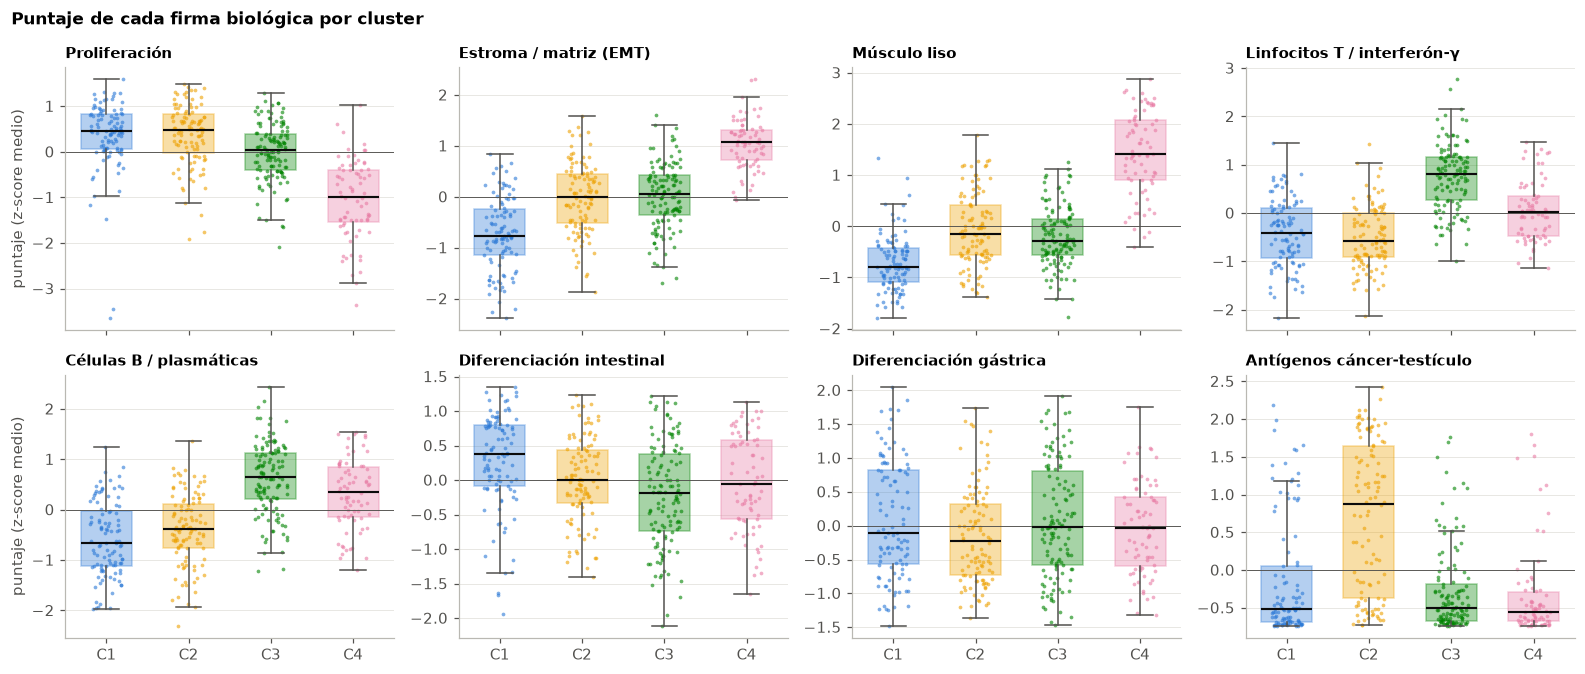

Puntaje medio por cluster (0 = promedio de la cohorte):


,Genes usados,C1,C2,C3,C4,eta²,p (Kruskal-Wallis)
Firma,,,,,,,
Proliferación,10/10,0.35,0.37,0.01,-1.04,0.31,4.4e-28
Estroma / matriz (EMT),12/12,-0.73,-0.02,0.01,1.04,0.43,1.0e-38
Músculo liso,8/8,-0.70,-0.07,-0.20,1.43,0.45,6.5e-40
Linfocitos T / interferón-γ,12/12,-0.42,-0.50,0.74,0.05,0.38,3.2e-34
Células B / plasmáticas,8/8,-0.58,-0.39,0.63,0.32,0.35,3.9e-31
Diferenciación intestinal,9/9,0.28,0.01,-0.22,-0.03,0.07,8.7e-07
Diferenciación gástrica,9/9,0.09,-0.15,0.08,-0.04,0.01,1.4e-01
Antígenos cáncer-testículo,6/8,-0.14,0.70,-0.29,-0.33,0.19,4.6e-17


Correlación de Spearman entre cada firma y los primeros componentes principales:


,PC1,PC2,PC3,PC4,PC5
Proliferación,-0.57,-0.17,-0.12,-0.06,0.49
Estroma / matriz (EMT),0.77,-0.02,0.00,0.35,0.32
Músculo liso,0.81,-0.10,0.04,0.16,-0.11
Linfocitos T / interferón-γ,0.26,0.75,-0.08,-0.05,0.33
Células B / plasmáticas,0.44,0.59,0.18,-0.47,-0.12
Diferenciación intestinal,-0.22,-0.18,0.55,0.03,0.05
Diferenciación gástrica,-0.02,0.13,0.47,-0.09,-0.38
Antígenos cáncer-testículo,-0.06,-0.34,-0.00,-0.33,0.21


In [34]:
# Firmas biológicas: conjuntos de genes bien conocidos definidos ANTES de mirar los clusters.
FIRMAS = {
    "Proliferación": ["MKI67", "TOP2A", "CDK1", "CCNB1", "BUB1", "AURKA", "UBE2C", "BIRC5", "TPX2", "CDC20"],
    "Estroma / matriz (EMT)": ["COL1A1", "COL1A2", "COL3A1", "SPARC", "DCN", "LUM", "VIM", "ZEB1", "ZEB2", "TWIST1", "FAP", "PDGFRB"],
    "Músculo liso": ["DES", "MYH11", "ACTG2", "CNN1", "LMOD1", "SYNPO2", "ACTA2", "TAGLN"],
    "Linfocitos T / interferón-γ": ["CD3D", "CD3E", "CD8A", "GZMA", "GZMB", "PRF1", "CXCL9", "CXCL10", "IFNG", "IDO1", "STAT1", "HLA-DRA"],
    "Células B / plasmáticas": ["MZB1", "JCHAIN", "CD79A", "MS4A1", "IGHM", "TNFRSF17", "CD19", "IGKC"],
    "Diferenciación intestinal": ["CDX1", "CDX2", "CDH17", "VIL1", "KRT20", "MUC2", "REG4", "TFF3", "LGALS4"],
    "Diferenciación gástrica": ["MUC5AC", "TFF1", "TFF2", "GKN1", "GKN2", "MUC6", "PGC", "CLDN18", "LIPF"],
    "Antígenos cáncer-testículo": ["MAGEA3", "MAGEA6", "MAGEA12", "MAGEA4", "MAGEA2", "CSAG1", "PRAME", "CTAG2"],
}
# símbolo -> identificador (si el símbolo se repite, el de mayor expresión media)
id_de = (pd.DataFrame({"gen": simbolo.values, "media": Xf.mean(axis=1).values, "id": Xf.index})
         .sort_values("media", ascending=False).drop_duplicates("gen").set_index("gen")["id"])
Zg = Xf.sub(Xf.mean(axis=1), axis=0).div(Xf.std(axis=1), axis=0)       # z-score por gen entre tumores

puntajes, filas = pd.DataFrame(index=tumores), []
for nombre, lista in FIRMAS.items():
    presentes = [g for g in lista if g in id_de.index]
    puntajes[nombre] = Zg.loc[id_de[presentes]].mean(axis=0)
    Hs, ps = stats.kruskal(*[puntajes.loc[(cl == c).values, nombre] for c in CL])
    filas.append({"Firma": nombre, "Genes usados": f"{len(presentes)}/{len(lista)}",
                  **{c: round(puntajes.loc[(cl == c).values, nombre].mean(), 2) for c in CL},
                  "eta²": round((Hs - K + 1) / (n_tot - K), 2), "p (Kruskal-Wallis)": f"{ps:.1e}"})
tab_firmas = pd.DataFrame(filas).set_index("Firma")

fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.2), sharex=True)
rng = np.random.default_rng(SEED)
for ax, nombre in zip(axes.ravel(), FIRMAS):
    datos = [puntajes.loc[(cl == c).values, nombre].values for c in CL]
    bp = ax.boxplot(datos, positions=range(K), widths=0.62, showfliers=False, patch_artist=True,
                    medianprops=dict(color=TINTA, lw=1.4), whiskerprops=dict(color=TINTA2), capprops=dict(color=TINTA2))
    for caja, color in zip(bp["boxes"], COL_CLUSTER):
        caja.set(facecolor=color, alpha=0.35, edgecolor=color)
    for i, d in enumerate(datos):
        ax.scatter(i + rng.uniform(-0.2, 0.2, len(d)), d, s=6, color=COL_CLUSTER[i], alpha=0.6, linewidths=0)
    ax.axhline(0, color=TINTA2, lw=0.6); ax.set_title(nombre, fontsize=10); ax.set_xticks(range(K)); ax.set_xticklabels(CL)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("puntaje (z-score medio)")
fig.suptitle("Puntaje de cada firma biológica por cluster", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()
print("Puntaje medio por cluster (0 = promedio de la cohorte):")
display(tab_firmas)

# Relación entre las firmas y los componentes principales (correlación de Spearman)
corr_pc = pd.DataFrame({pc: [stats.spearmanr(P[pc], puntajes[f])[0] for f in FIRMAS] for pc in P.columns[:5]}, index=list(FIRMAS)).round(2)
print("Correlación de Spearman entre cada firma y los primeros componentes principales:")
display(corr_pc)

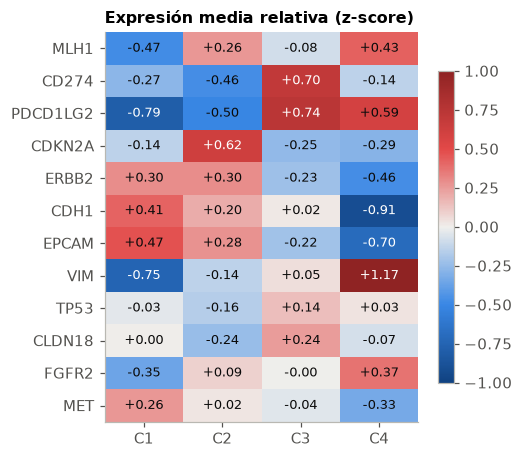

,C1,C2,C3,C4,FDR global
MLH1,-0.47,0.26,-0.08,0.43,1.5e-05
CD274,-0.27,-0.46,0.70,-0.14,3.8e-21
PDCD1LG2,-0.79,-0.50,0.74,0.59,3.7e-41
CDKN2A,-0.14,0.62,-0.25,-0.29,1.1e-09
ERBB2,0.30,0.30,-0.23,-0.46,4.6e-12
CDH1,0.41,0.20,0.02,-0.91,2.2e-15
EPCAM,0.47,0.28,-0.22,-0.70,1.3e-18
VIM,-0.75,-0.14,0.05,1.17,8.9e-35
TP53,-0.03,-0.16,0.14,0.03,1.2e-01
CLDN18,0.00,-0.24,0.24,-0.07,1.5e-04


MLH1: mediana 3.80; umbral de «muy bajo» (mediana − 3 MAD) = 2.17; tumores por debajo: 36 (9 %)


col_0,MLH1 muy bajo,MLH1 normal,% MLH1 muy bajo
row_0,,,
C1,27,77,26.0
C2,3,105,2.8
C3,6,120,4.8
C4,0,74,0.0


Chi² MLH1 bajo vs. cluster: p = 1.8e-11


In [35]:
# Genes individuales con relevancia clínica o ligados a los subtipos moleculares publicados
GENES_CLAVE = ["MLH1", "CD274", "PDCD1LG2", "CDKN2A", "ERBB2", "CDH1", "EPCAM", "VIM", "TP53", "CLDN18", "FGFR2", "MET"]
presentes = [g for g in GENES_CLAVE if g in id_de.index]
medias = pd.DataFrame({c: Zg.loc[id_de[presentes], (cl == c).values].mean(axis=1).values for c in CL}, index=presentes)
medias["FDR global"] = [f"{genes.loc[id_de[g], 'FDR']:.1e}" for g in presentes]

fig, ax = plt.subplots(figsize=(4.6, 4.6))
vals = medias[CL].values.astype(float)
im = ax.imshow(vals, cmap=CMAP_DIV, vmin=-1, vmax=1, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(K):
        ax.text(j, i, f"{vals[i, j]:+.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(vals[i, j]) > 0.6 else TINTA)
ax.set_xticks(range(K)); ax.set_xticklabels(CL); ax.set_yticks(range(len(presentes))); ax.set_yticklabels(presentes)
ax.grid(False); ax.set_title("Expresión media relativa (z-score)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
display(medias.round(2))

# MLH1: su silenciamiento epigenético es la causa habitual de inestabilidad de microsatélites (MSI)
mlh1 = Xf.loc[id_de["MLH1"]]
umbral_mlh1 = mlh1.median() - 3 * 1.4826 * np.median(np.abs(mlh1 - mlh1.median()))
bajo = mlh1 < umbral_mlh1
tab_mlh1 = pd.crosstab(cl.values, np.where(bajo.values, "MLH1 muy bajo", "MLH1 normal"))
tab_mlh1["% MLH1 muy bajo"] = (100 * tab_mlh1["MLH1 muy bajo"] / tab_mlh1.sum(axis=1)).round(1)
print(f"MLH1: mediana {mlh1.median():.2f}; umbral de «muy bajo» (mediana − 3 MAD) = {umbral_mlh1:.2f}; tumores por debajo: {int(bajo.sum())} ({100 * bajo.mean():.0f} %)")
display(tab_mlh1)
print(f"Chi² MLH1 bajo vs. cluster: p = {stats.chi2_contingency(tab_mlh1.iloc[:, :2])[1]:.1e}")

### 7.2 Interpretación molecular de los clusters

Combinando marcadores, firmas y genes individuales, cada cluster tiene un perfil reconocible:

| Cluster | n | Rasgos de expresión | Lectura biológica |
|---|---|---|---|
| **C1** | 104 | Firma intestinal más alta (+0.28), proliferación alta (+0.35); los valores más bajos de estroma (−0.73), músculo liso (−0.70), linfocitos T (−0.42) y células B (−0.58); *EPCAM* y *CDH1* altos | **Epitelial de tipo intestinal**: tumores con mucho contenido epitelial, diferenciados hacia intestino y con poco tejido acompañante |
| **C2** | 108 | Antígenos cáncer-testículo (+0.70), proliferación alta (+0.37), linfocitos T en el nivel más bajo (−0.50), *CDKN2A* alto, *CD274* (PD-L1) bajo | **Proliferativo e inmune-frío**, con reactivación de genes embrionarios y de línea germinal |
| **C3** | 126 | Linfocitos T / interferón-γ (+0.74) y células B (+0.63) en el nivel más alto; *CD274* (PD-L1, +0.70) y *PDCD1LG2* (PD-L2, +0.74) altos | **Inmune-inflamado**: tumores muy infiltrados por linfocitos y células plasmáticas |
| **C4** | 74 | Músculo liso (+1.43) y estroma (+1.04) muy altos, *VIM* alto; proliferación (−1.04), *CDH1* (−0.91) y *EPCAM* (−0.70) bajos | **Estromal / mesenquimal**: poco epitelio tumoral, mucha matriz y músculo, baja proliferación |

**Observaciones adicionales:**

- **Las firmas confirman la lectura de los componentes principales.** PC1 se correlaciona con músculo liso (ρ = 0.81) y estroma (0.77) y, en sentido inverso, con proliferación (−0.57). PC2 se correlaciona con linfocitos T (0.75) y células B (0.59). PC3 con diferenciación intestinal (0.55) y gástrica (0.47).
- **La firma de diferenciación gástrica no distingue a los clusters** (p = 0.14). Los genes de mucosa gástrica son los más variables del conjunto de datos, pero su variación no se alinea con esta partición.
- **C1 concentra los tumores con *MLH1* apagado:** 27 de sus 104 tumores (26 %) tienen una expresión de *MLH1* muy baja, frente a 0–5 % en los demás (p = 2 × 10⁻¹¹). El silenciamiento de *MLH1* es la causa habitual de la inestabilidad de microsatélites (MSI), así que una parte de C1 probablemente corresponde a tumores MSI. Es una inferencia indirecta: aquí no hay datos de MSI.
- **C3 tiene la expresión más alta de PD-L1 y PD-L2**, los ligandos que bloquean a los linfocitos T y que son el blanco de la inmunoterapia.
- ***ERBB2* (HER2)** es más alto en C1 y C2 y más bajo en C4. ***TP53*** no difiere a nivel de expresión (FDR = 0.12), lo esperable porque sus alteraciones son mutaciones, no cambios de cantidad de ARN.

**Una cautela importante sobre C4.** El RNA-seq se hizo sobre un fragmento de tejido completo, que mezcla células tumorales con fibroblastos, músculo, vasos y células inmunes. Un perfil «estromal» puede significar que las células tumorales adoptaron un programa mesenquimal, pero también, simplemente, que la muestra contenía pocas células tumorales y mucha pared gástrica. La baja expresión de *CDH1* y *EPCAM* y la baja proliferación son compatibles con ambas explicaciones. Algo parecido vale para C3 (más células inmunes en la muestra) y para C1 (mayor pureza tumoral). Los clusters describen la **composición del tejido** tanto como la biología de la célula cancerosa.

## 8. Interpretación de los clusters: análisis clínico

Las variables clínicas no participaron en la construcción de los clusters, así que aquí las pruebas estadísticas **sí** son válidas como contraste independiente: si los grupos fueran arbitrarios, no tendrían por qué diferir en histología, estadio o edad.

- **Variables categóricas:** prueba chi² de independencia. El tamaño del efecto se mide con la V de Cramér (0 = sin relación, 1 = relación perfecta; como orientación, 0.1 pequeño, 0.3 mediano).
- **Variables numéricas (edad):** Kruskal-Wallis.
- **Comparaciones múltiples:** los valores p de las 10 variables se corrigen con Benjamini-Hochberg.

Cada prueba usa los pacientes con dato disponible para esa variable. Se incluye el **centro de origen** como control: no es una variable clínica, pero si se asocia con los clusters hay que tenerlo en cuenta al interpretar lo demás.

In [36]:
# Variables categóricas: chi² de independencia + V de Cramér.  Variables numéricas: Kruskal-Wallis + eta².
VARS_CAT = ["Sexo", "Raza", "Histología", "Región", "Estadio", "T", "N", "M", "Centro"]
filas, tablas = [], {}
for v in VARS_CAT:
    ct = pd.crosstab(meta[v], meta["Cluster"])
    chi2, p, gl, esperado = stats.chi2_contingency(ct)
    n = ct.values.sum()
    filas.append({"Variable": v, "n": int(n), "Prueba": f"chi² ({gl} gl)", "Estadístico": round(chi2, 1), "p": p,
                  "Tamaño de efecto": f"V = {np.sqrt(chi2 / (n * (min(ct.shape) - 1))):.2f}",
                  "Celdas con esperado < 5": f"{int((esperado < 5).sum())}/{esperado.size}"})
    tablas[v] = ct
ok = meta["Edad"].notna()
Hed, ped = stats.kruskal(*[meta.loc[ok & (cl == c), "Edad"] for c in CL])
filas.append({"Variable": "Edad", "n": int(ok.sum()), "Prueba": "Kruskal-Wallis", "Estadístico": round(Hed, 1), "p": ped,
              "Tamaño de efecto": f"eta² = {max(0, (Hed - K + 1) / (ok.sum() - K)):.2f}", "Celdas con esperado < 5": "–"})
asoc_clin = pd.DataFrame(filas).set_index("Variable")
asoc_clin["FDR (BH)"] = bh(asoc_clin["p"].values)
asoc_clin = asoc_clin.sort_values("p")
mostrar = asoc_clin.copy()
mostrar["p"] = mostrar["p"].map(lambda v: f"{v:.1e}"); mostrar["FDR (BH)"] = mostrar["FDR (BH)"].map(lambda v: f"{v:.1e}")
display(mostrar)

,n,Prueba,Estadístico,p,Tamaño de efecto,Celdas con esperado < 5,FDR (BH)
Variable,,,,,,,
Histología,412,chi² (9 gl),70.9,1.0e-11,V = 0.24,3/16,1.0e-10
Centro,412,chi² (21 gl),84.0,1.7e-09,V = 0.26,4/32,8.6e-09
T,404,chi² (9 gl),36.2,3.7e-05,V = 0.17,1/16,1.2e-04
Estadio,388,chi² (9 gl),21.8,9.6e-03,V = 0.14,0/16,2.4e-02
Edad,407,Kruskal-Wallis,10.9,1.2e-02,eta² = 0.02,–,2.5e-02
Región,394,chi² (6 gl),14.8,2.2e-02,V = 0.14,0/12,3.7e-02
Raza,359,chi² (6 gl),8.6,2.0e-01,V = 0.11,4/12,2.8e-01
Sexo,412,chi² (3 gl),2.1,5.6e-01,V = 0.07,0/8,6.7e-01
N,393,chi² (9 gl),7.1,6.3e-01,V = 0.08,0/16,6.7e-01


In [37]:
# Tabla descriptiva: características clínicas por cluster (n y % dentro del cluster)
bloques = []
fila_n = pd.DataFrame([[int((cl == c).sum()) for c in CL] + [len(cl)]], columns=CL + ["Total"],
                      index=pd.MultiIndex.from_tuples([("Tumores", "n")]))
bloques.append(fila_n.astype(str))
ed = pd.DataFrame([[f"{meta.loc[cl == c, 'Edad'].median():.0f} ({meta.loc[cl == c, 'Edad'].quantile(.25):.0f}–{meta.loc[cl == c, 'Edad'].quantile(.75):.0f})" for c in CL]
                   + [f"{meta['Edad'].median():.0f} ({meta['Edad'].quantile(.25):.0f}–{meta['Edad'].quantile(.75):.0f})"]],
                  columns=CL + ["Total"], index=pd.MultiIndex.from_tuples([("Edad", "mediana (Q1–Q3)")]))
bloques.append(ed)
ORDENES = {"Estadio": ["I", "II", "III", "IV"], "Histología": ["Intestinal", "Difuso", "Mucinoso", "No especificado"],
           "Región": ["Cardias", "Fondo/cuerpo", "Antro/píloro"]}
for v in ["Sexo", "Histología", "Región", "Estadio", "T", "N", "M", "Raza"]:
    ct = tablas[v]
    if v in ORDENES:
        ct = ct.reindex(ORDENES[v])
    tot = ct.sum(axis=1)
    txt = pd.DataFrame({c: [f"{ct.loc[r, c]} ({100 * ct.loc[r, c] / ct[c].sum():.0f} %)" for r in ct.index] for c in CL}, index=ct.index)
    txt["Total"] = [f"{tot[r]} ({100 * tot[r] / tot.sum():.0f} %)" for r in ct.index]
    txt.index = pd.MultiIndex.from_product([[v], ct.index])
    bloques.append(txt)
display(pd.concat(bloques))

C1          C2          C3          C4       Total
Tumores    n                           104         108         126          74         412
Edad       mediana (Q1–Q3)      68 (60–73)  67 (58–72)  68 (59–75)  62 (54–71)  67 (58–73)
Sexo       Hombre                68 (65 %)   75 (69 %)   80 (63 %)   44 (59 %)  267 (65 %)
           Mujer                 36 (35 %)   33 (31 %)   46 (37 %)   30 (41 %)  145 (35 %)
Histología Intestinal            58 (56 %)   53 (49 %)   40 (32 %)     6 (8 %)  157 (38 %)
           Difuso                11 (11 %)   11 (10 %)   27 (21 %)   30 (41 %)   79 (19 %)
           Mucinoso                3 (3 %)     3 (3 %)     4 (3 %)    9 (12 %)    19 (5 %)
           No especificado       32 (31 %)   41 (38 %)   55 (44 %)   29 (39 %)  157 (38 %)
Región     Cardias               27 (28 %)   33 (31 %)   29 (24 %)   10 (14 %)   99 (25 %)
           Fondo/cuerpo          35 (36 %)   34 (32 %)   55 (45 %)   22 (32 %)  146 (37 %)
           Antro/píloro          36 (37 %)   39 (37 %)   37 (31 %)   37 (54 %)  149 (38 %)
Estadio    I                     28 (29 %)   14 (14 %)     9 (8 %)    7 (10 %)   58 (15 %)
           II                    26 (27 %)   33 (32 %)   38 (32 %)   25 (36 %)  122 (31 %)
           III                   37 (38 %)   44 (43 %)   56 (48 %)   32 (46 %)  169 (44 %)
           IV                      7 (7 %)   12 (12 %)   14 (12 %)     6 (9 %)   39 (10 %)
T          T1                    16 (15 %)     4 (4 %)     2 (2 %)     0 (0 %)    22 (5 %)
           T2                    26 (25 %)   22 (21 %)   25 (20 %)   15 (21 %)   88 (22 %)
           T3                    42 (40 %)   55 (52 %)   52 (42 %)   32 (45 %)  181 (45 %)
           T4                    20 (19 %)   25 (24 %)   44 (36 %)   24 (34 %)  113 (28 %)
N          N0                    39 (40 %)   30 (29 %)   33 (27 %)   22 (31 %)  124 (32 %)
           N1                    23 (23 %)   32 (31 %)   33 (27 %)   21 (30 %)  109 (28 %)
           N2                    18 (18 %)   22 (21 %)   28 (23 %)   10 (14 %)   78 (20 %)
           N3                    18 (18 %)   20 (19 %)   27 (22 %)   17 (24 %)   82 (21 %)
M          M0                    94 (96 %)   94 (93 %)  112 (93 %)   65 (92 %)  365 (93 %)
           M1                      4 (4 %)     7 (7 %)     9 (7 %)     6 (8 %)    26 (7 %)
Raza       Asiática              27 (31 %)   22 (23 %)   20 (19 %)   18 (25 %)   87 (24 %)
           Blanca                55 (63 %)   70 (73 %)   82 (78 %)   53 (75 %)  260 (72 %)
           Negra/afroamericana     5 (6 %)     4 (4 %)     3 (3 %)     0 (0 %)    12 (3 %)

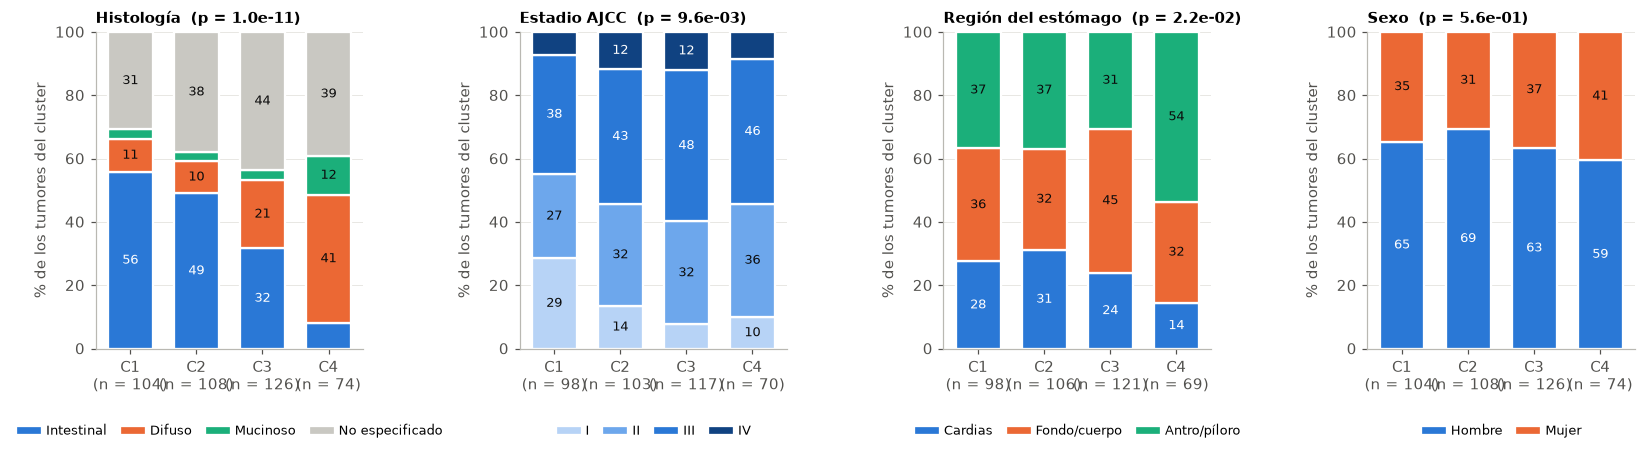

In [38]:
def barras_apiladas(ax, v, orden, colores, titulo):
    ct = tablas[v].reindex(orden)
    pct = 100 * ct / ct.sum(axis=0)
    base = np.zeros(K)
    for cat, color in zip(orden, colores):
        ax.bar(range(K), pct.loc[cat].values, bottom=base, color=color, width=0.68, edgecolor="white", linewidth=1.5, label=cat)
        for i, val in enumerate(pct.loc[cat].values):
            if val >= 9:
                oscuro = color in ("#104281", "#1c5cab", "#2a78d6", "#008300", "#0d366b")
                ax.text(i, base[i] + val / 2, f"{val:.0f}", ha="center", va="center", fontsize=8.5, color="white" if oscuro else TINTA)
        base += pct.loc[cat].values
    fila = asoc_clin.loc[v]
    ax.set_xticks(range(K)); ax.set_xticklabels([f"{c}\n(n = {ct[c].sum()})" for c in CL])
    ax.set_ylim(0, 100); ax.set_ylabel("% de los tumores del cluster"); ax.grid(axis="x", visible=False)
    ax.set_title(f"{titulo}  (p = {fila['p']:.1e})", fontsize=10)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=min(4, len(orden)), handletextpad=0.3, columnspacing=1.0, fontsize=8.5)

fig, axes = plt.subplots(1, 4, figsize=(15, 4.3))
barras_apiladas(axes[0], "Histología", ORDENES["Histología"], ["#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2"], "Histología")
barras_apiladas(axes[1], "Estadio", ORDENES["Estadio"], ["#b7d3f6", "#6da7ec", "#2a78d6", "#104281"], "Estadio AJCC")
barras_apiladas(axes[2], "Región", ORDENES["Región"], ["#2a78d6", "#eb6834", "#1baf7a"], "Región del estómago")
barras_apiladas(axes[3], "Sexo", ["Hombre", "Mujer"], ["#2a78d6", "#eb6834"], "Sexo")
plt.tight_layout(); plt.show()

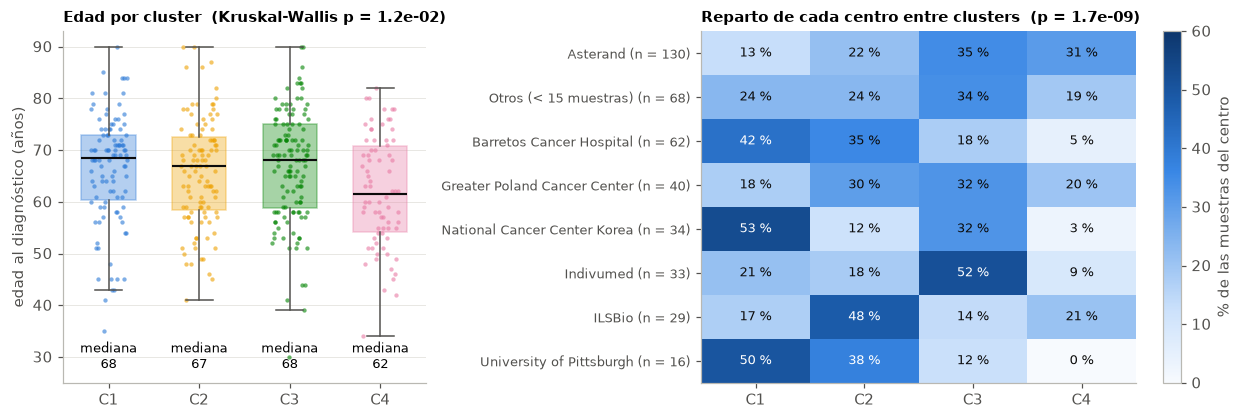

C1: mediana 68 vs. 66 años en el resto   (Mann-Whitney p = 2.4e-01)
C2: mediana 67 vs. 68 años en el resto   (Mann-Whitney p = 8.6e-01)
C3: mediana 68 vs. 67 años en el resto   (Mann-Whitney p = 9.5e-02)
C4: mediana 62 vs. 68 años en el resto   (Mann-Whitney p = 1.9e-03)


In [39]:
# Edad por cluster
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
datos = [meta.loc[ok & (cl == c), "Edad"].values for c in CL]
bp = ax.boxplot(datos, positions=range(K), widths=0.6, showfliers=False, patch_artist=True,
                medianprops=dict(color=TINTA, lw=1.4), whiskerprops=dict(color=TINTA2), capprops=dict(color=TINTA2))
for caja, color in zip(bp["boxes"], COL_CLUSTER):
    caja.set(facecolor=color, alpha=0.35, edgecolor=color)
rng = np.random.default_rng(SEED)
for i, d in enumerate(datos):
    ax.scatter(i + rng.uniform(-0.2, 0.2, len(d)), d, s=8, color=COL_CLUSTER[i], alpha=0.6, linewidths=0)
    ax.text(i, 27, f"mediana\n{np.median(d):.0f}", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(range(K)); ax.set_xticklabels(CL); ax.set_ylabel("edad al diagnóstico (años)"); ax.set_ylim(25, 93)
ax.set_title(f"Edad por cluster  (Kruskal-Wallis p = {ped:.1e})", fontsize=10); ax.grid(axis="x", visible=False)

# Centro de origen: % de cada centro que cae en cada cluster (posible confusión técnica)
ct = tablas["Centro"]; ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]
pct = 100 * ct.div(ct.sum(axis=1), axis=0)
ax = axes[1]
im = ax.imshow(pct.values, cmap=CMAP_SEQ, vmin=0, vmax=60, aspect="auto")
for i in range(pct.shape[0]):
    for j in range(K):
        ax.text(j, i, f"{pct.values[i, j]:.0f} %", ha="center", va="center", fontsize=8.5, color="white" if pct.values[i, j] > 36 else TINTA)
ax.set_xticks(range(K)); ax.set_xticklabels(CL)
ax.set_yticks(range(pct.shape[0])); ax.set_yticklabels([f"{r} (n = {ct.loc[r].sum()})" for r in pct.index], fontsize=8.5)
ax.grid(False); ax.set_title(f"Reparto de cada centro entre clusters  (p = {asoc_clin.loc['Centro', 'p']:.1e})", fontsize=10)
fig.colorbar(im, ax=ax, label="% de las muestras del centro")
plt.tight_layout(); plt.show()

# Comparaciones de edad: cada cluster contra el resto
for c in CL:
    a, b = meta.loc[ok & (cl == c), "Edad"], meta.loc[ok & (cl != c), "Edad"]
    print(f"{c}: mediana {a.median():.0f} vs. {b.median():.0f} años en el resto   (Mann-Whitney p = {stats.mannwhitneyu(a, b)[1]:.1e})")

In [40]:
# ¿La asociación con la histología se mantiene dentro de un mismo centro? (control del efecto de lote)
filas = []
for nombre_c, sub in [("Todos los centros", meta), ("Solo Asterand", meta[meta["Centro"] == "Asterand"]),
                      ("Todos menos Asterand", meta[meta["Centro"] != "Asterand"])]:
    s2 = sub[sub["Histología"].isin(["Intestinal", "Difuso"])]
    ct = pd.crosstab(s2["Histología"], s2["Cluster"])
    chi2, p, gl, _ = stats.chi2_contingency(ct)
    filas.append({"Subconjunto": nombre_c, "n (intestinal + difuso)": len(s2),
                  **{f"% difuso en {c}": round(100 * ct.loc["Difuso", c] / ct[c].sum(), 0) for c in CL},
                  "V de Cramér": round(np.sqrt(chi2 / len(s2)), 2), "p": f"{p:.1e}"})
display(pd.DataFrame(filas).set_index("Subconjunto"))

,n (intestinal + difuso),% difuso en C1,% difuso en C2,% difuso en C3,% difuso en C4,V de Cramér,p
Subconjunto,,,,,,,
Todos los centros,236,16.0,17.0,40.0,83.0,0.50,1.1e-12
Solo Asterand,30,0.0,0.0,0.0,92.0,0.93,9.3e-06
Todos menos Asterand,206,17.0,20.0,44.0,79.0,0.43,2.0e-08


### 8.1 Lectura de las asociaciones clínicas

**Variables asociadas con los clusters** (FDR < 0.05):

- **Histología** (p = 1.0 × 10⁻¹¹, V = 0.24). Es la asociación clínica más fuerte. **C4 concentra los tumores difusos**: 41 % de sus tumores son difusos y otro 12 % mucinosos, y solo 8 % intestinales. En C1 es al revés: 56 % intestinales y 11 % difusos. Si se consideran solo los tumores clasificados como intestinal o difuso, el porcentaje de difusos sube de forma ordenada: 16 % en C1, 17 % en C2, 40 % en C3 y **83 % en C4**.
- **Profundidad de invasión, T** (p = 3.7 × 10⁻⁵, V = 0.17). 16 de los 22 tumores T1 (los más superficiales) están en C1, donde son el 15 %, frente a 0–4 % en los demás. Los T4 son más frecuentes en C3 (36 %) y C4 (34 %) que en C1 (19 %).
- **Estadio** (p = 0.010, V = 0.14). Refleja lo mismo: 29 % de C1 está en estadio I, frente a 8–14 % en los otros clusters.
- **Edad** (p = 0.012). Los pacientes de **C4 son más jóvenes**: mediana de 62 años frente a 68 en el resto (p = 0.002). Los otros tres clusters no difieren entre sí.
- **Región del estómago** (p = 0.022, V = 0.14). C4 predomina en antro y píloro (54 %) y es raro en el cardias (14 %, frente a 24–31 % en los demás).

**Variables sin asociación:** sexo (p = 0.56), raza (p = 0.20), ganglios N (p = 0.63) y metástasis M (p = 0.67). Que el sexo no se asocie confirma, de nuevo, que los genes ligados al sexo se eliminaron bien.

**El centro de origen** (p = 1.7 × 10⁻⁹, V = 0.26) se asocia con los clusters tanto como la histología. Por ejemplo, Asterand aporta el 31 % de sus muestras a C4 mientras que el National Cancer Center de Corea aporta el 3 % y Pittsburgh ninguna; la mitad de las muestras de Corea y de Pittsburgh están en C1. Hay dos lecturas posibles y no excluyentes: diferencias técnicas (cómo se toma y procesa el tejido; cuánta pared gástrica entra en el fragmento) y diferencias reales en los pacientes de cada centro. Como comprobación, la asociación con la histología **se mantiene al excluir a Asterand** (difusos: 17 %, 20 %, 44 % y 79 % de C1 a C4; p = 2 × 10⁻⁸) y también dentro de Asterand, aunque allí solo 30 tumores tienen subtipo. El gradiente histológico, por tanto, no es un artefacto de un centro.

Varias tablas tienen celdas con frecuencia esperada menor a 5 (señaladas en la tabla de pruebas), sobre todo raza y centro, por lo que sus valores p son aproximados.

### 8.2 Supervivencia global

Se estima la supervivencia de cada cluster con el método de **Kaplan-Meier**, que aprovecha también a los pacientes que seguían vivos al final del seguimiento (censurados), y se comparan las curvas con la prueba **log-rank**. Como el estadio es el factor pronóstico más fuerte y difiere entre clusters, se añade una versión **estratificada por estadio**, que compara los clusters solo entre pacientes del mismo estadio. Ambos métodos se implementan directamente con `numpy` para no depender de bibliotecas adicionales.

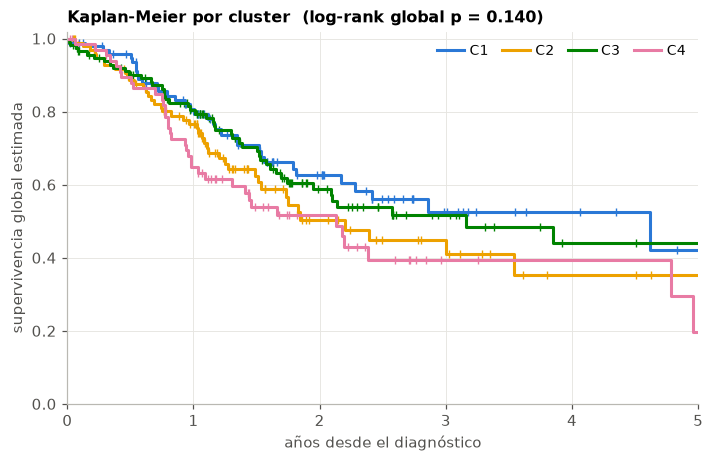

,n,Fallecimientos,Mediana de supervivencia (años),Supervivencia a 2 años (%),En riesgo a 2 años
Cluster,,,,,
C1,97,34,4.62,63.0,33
C2,101,43,2.20,50.0,21
C3,117,46,3.16,59.0,36
C4,70,36,2.13,52.0,18


Log-rank global entre los 4 clusters:           chi² = 5.48 (3 gl), p = 0.140   (n = 385)
Log-rank estratificado por estadio:             chi² = 5.40 (3 gl), p = 0.145   (n = 371)
Referencia, log-rank entre estadios I–IV:       chi² = 20.45 (3 gl), p = 1.4e-04


,chi²,p,FDR (BH)
Comparación,,,
C1 vs. resto,1.84,0.175,0.312
C2 vs. resto,1.02,0.312,0.312
C3 vs. resto,1.15,0.283,0.312
C4 vs. resto,3.11,0.078,0.311


In [41]:
def kaplan_meier(t, e):
    """Estimador de Kaplan-Meier. Devuelve tiempos, supervivencia y n.º en riesgo."""
    t, e = np.asarray(t, float), np.asarray(e, int)
    tiempos = np.unique(t[e == 1])
    S, s, riesgo = [], 1.0, []
    for ti in tiempos:
        n_i = (t >= ti).sum(); d_i = ((t == ti) & (e == 1)).sum()
        s *= 1 - d_i / n_i; S.append(s); riesgo.append(n_i)
    return tiempos, np.array(S), np.array(riesgo)

def mediana_km(t, e):
    tiempos, S, _ = kaplan_meier(t, e)
    return tiempos[S <= 0.5][0] if (S <= 0.5).any() else np.nan

def logrank(t, e, g, estratos=None):
    """Prueba log-rank para 2 o más grupos, opcionalmente estratificada. Devuelve (chi², gl, p)."""
    t, e, g = np.asarray(t, float), np.asarray(e, int), np.asarray(g)
    grupos = pd.unique(g); k = len(grupos)
    estratos = np.zeros(len(t), int) if estratos is None else np.asarray(estratos)
    OE, V = np.zeros(k), np.zeros((k, k))
    for s in pd.unique(estratos):
        ms = estratos == s
        for ti in np.unique(t[ms & (e == 1)]):
            en_riesgo = ms & (t >= ti)
            n_j = np.array([(en_riesgo & (g == x)).sum() for x in grupos], float)
            d_j = np.array([(ms & (t == ti) & (e == 1) & (g == x)).sum() for x in grupos], float)
            n, d = n_j.sum(), d_j.sum()
            OE += d_j - d * n_j / n
            if n > 1:
                V += d * (n - d) / (n - 1) * (np.diag(n_j / n) - np.outer(n_j, n_j) / n ** 2)
    chi2 = OE[:-1] @ np.linalg.solve(V[:-1, :-1], OE[:-1])
    return chi2, k - 1, stats.chi2.sf(chi2, k - 1)

sv = meta[meta["OS"].notna() & meta["OS_dias"].notna()].copy()
sv["anios"] = sv["OS_dias"] / 365.25

fig, ax = plt.subplots(figsize=(7.4, 4.4))
filas = []
for i, c in enumerate(CL):
    d = sv[sv["Cluster"] == c]
    tt, S, _ = kaplan_meier(d["anios"], d["OS"])
    ax.step(np.r_[0, tt, d["anios"].max()], np.r_[1, S, S[-1]], where="post", color=COL_CLUSTER[i], lw=2, label=c)
    cens = d.loc[d["OS"] == 0, "anios"].values
    s_cens = np.array([np.r_[1, S][np.searchsorted(tt, x, side="right")] for x in cens])
    ax.scatter(cens, s_cens, marker="|", s=28, color=COL_CLUSTER[i], linewidths=0.9)
    med = mediana_km(d["anios"], d["OS"])
    filas.append({"Cluster": c, "n": len(d), "Fallecimientos": int(d["OS"].sum()),
                  "Mediana de supervivencia (años)": round(med, 2) if not np.isnan(med) else "no alcanzada",
                  "Supervivencia a 2 años (%)": round(100 * np.r_[1, S][np.searchsorted(tt, 2, side="right")], 0),
                  "En riesgo a 2 años": int((d["anios"] >= 2).sum())})
ax.set_xlim(0, 5); ax.set_ylim(0, 1.02); ax.set_xlabel("años desde el diagnóstico"); ax.set_ylabel("supervivencia global estimada")
chi2_g, gl_g, p_g = logrank(sv["anios"], sv["OS"], sv["Cluster"].astype(str))
ax.set_title(f"Kaplan-Meier por cluster  (log-rank global p = {p_g:.3f})")
ax.legend(loc="upper right", ncol=4, handletextpad=0.4, columnspacing=1.0)
plt.show()
display(pd.DataFrame(filas).set_index("Cluster"))

# Pruebas log-rank
sv_e = sv[sv["Estadio"].notna()]
chi2_e, gl_e, p_e = logrank(sv_e["anios"], sv_e["OS"], sv_e["Cluster"].astype(str), estratos=sv_e["Estadio"].values)
chi2_s, _, p_s = logrank(sv_e["anios"], sv_e["OS"], sv_e["Estadio"].values)
print(f"Log-rank global entre los 4 clusters:           chi² = {chi2_g:.2f} ({gl_g} gl), p = {p_g:.3f}   (n = {len(sv)})")
print(f"Log-rank estratificado por estadio:             chi² = {chi2_e:.2f} ({gl_e} gl), p = {p_e:.3f}   (n = {len(sv_e)})")
print(f"Referencia, log-rank entre estadios I–IV:       chi² = {chi2_s:.2f} (3 gl), p = {p_s:.1e}")
pares = []
for c in CL:
    g = np.where(sv["Cluster"] == c, c, "resto")
    x2, _, pp = logrank(sv["anios"], sv["OS"], g)
    pares.append({"Comparación": f"{c} vs. resto", "chi²": round(x2, 2), "p": pp})
pares = pd.DataFrame(pares).set_index("Comparación"); pares["FDR (BH)"] = bh(pares["p"].values)
display(pares.round(3))

### 8.3 Lectura de la supervivencia

- **No hay diferencias estadísticamente significativas** entre los cuatro clusters (log-rank global p = 0.140). El resultado es prácticamente igual al estratificar por estadio (p = 0.145), así que tampoco hay una diferencia oculta por el estadio.
- **El orden observado es el esperado biológicamente**, pero no pasa de tendencia: C1 tiene la mediana de supervivencia más larga (4.6 años; 63 % vivos a los 2 años) y C4 y C2 las más cortas (2.1 y 2.2 años; 52 % y 50 % a los 2 años). La comparación más cercana a la significancia es C4 contra el resto (p = 0.078, que queda en 0.31 tras corregir por las cuatro comparaciones).
- **El análisis tiene poca potencia.** La mediana de seguimiento es de 466 días y a los 2 años quedan entre 18 y 36 pacientes en riesgo por cluster. Con estos números solo se detectarían diferencias grandes. Como referencia, el estadio sí separa las curvas con claridad en esta misma cohorte (p = 1 × 10⁻⁴).

La conclusión correcta no es «los clusters no influyen en el pronóstico» sino «**estos datos no permiten afirmarlo**».

### 8.4 Síntesis clínica

| Cluster | Perfil molecular | Rasgos clínicos distintivos |
|---|---|---|
| **C1** | Epitelial de tipo intestinal | Histología intestinal (56 %), más tumores tempranos (29 % en estadio I, 15 % T1), 26 % con *MLH1* apagado |
| **C2** | Proliferativo e inmune-frío | Histología intestinal (49 %); sin rasgos clínicos propios |
| **C3** | Inmune-inflamado | Histología mixta, más tumores T4 (36 %), más frecuente en fondo y cuerpo (45 %) |
| **C4** | Estromal / mesenquimal | Histología difusa (41 %) y mucinosa (12 %), pacientes más jóvenes (mediana 62 años), localización antral (54 %) |

Los clusters, construidos solo con expresión, **recuperan diferencias clínicas que no se les mostraron**, sobre todo la distinción intestinal/difuso de Lauren. Es el principal argumento a favor de que la partición captura biología real y no solo ruido. El tamaño de esas asociaciones es moderado (V entre 0.14 y 0.24): hay tendencias claras, no una correspondencia uno a uno.

## 9. Discusión frente a la literatura

### 9.1 Artículo de referencia

**The Cancer Genome Atlas Research Network. *Comprehensive molecular characterization of gastric adenocarcinoma*. Nature, 2014** [1]. Es el estudio que generó los datos que se analizan aquí.

**Enfoque del artículo.** Los autores caracterizaron 295 adenocarcinomas gástricos primarios, congelados en fresco y sin tratamiento previo, con seis plataformas moleculares: número de copias, secuenciación del exoma, metilación del ADN, expresión de ARN mensajero, expresión de microARN y proteínas. Primero aplicaron clustering no supervisado a cada plataforma por separado y después integraron los resultados. Propusieron cuatro subtipos:

| Subtipo TCGA | Frecuencia | Rasgos principales |
|---|---|---|
| **EBV** (positivos para el virus de Epstein-Barr) | ~9 % | Mutaciones de *PIK3CA*, hipermetilación extrema del ADN, amplificación de *JAK2*, *CD274* (PD-L1) y *PDCD1LG2* (PD-L2) |
| **MSI** (inestabilidad de microsatélites) | ~22 % | Tasa de mutación muy alta, hipermetilación con silenciamiento de *MLH1* |
| **GS** (genómicamente estables) | ~20 % | Enriquecidos en histología difusa (73 % de los tumores GS), alteraciones en genes de adhesión celular (*CDH1*, *RHOA*) |
| **CIN** (inestabilidad cromosómica) | ~50 % | Aneuploidía marcada, mutaciones de *TP53* y amplificación de receptores tirosina-cinasa |

Un segundo estudio útil para comparar es el del **Asian Cancer Research Group** (Cristescu et al., *Nature Medicine*, 2015) [2], que clasificó 300 tumores usando principalmente **expresión génica**, como aquí. Describió cuatro subtipos: uno mesenquimal (MSS/EMT) formado sobre todo por tumores difusos, de pacientes más jóvenes y con el peor pronóstico; uno MSI, con el mejor pronóstico; y dos intermedios definidos por la actividad de TP53.

### 9.2 Similitudes

- **Datos y cohorte.** Se usan los mismos tumores, en una versión ampliada (412 frente a 295) y reprocesada por GDC con una metodología más reciente.
- **Estrategia.** Ambos trabajos parten de clustering no supervisado y después buscan qué caracteriza a cada grupo y cómo se relaciona con la clínica.
- **El grupo estromal/difuso.** El hallazgo más sólido de este reporte coincide con los dos artículos. C4 reproduce los rasgos del subtipo GS de TCGA y, sobre todo, del MSS/EMT del ACRG: histología difusa (83 % de los tumores de C4 clasificados como intestinal o difuso; TCGA reporta 73 % de difusos en GS, con un denominador algo distinto), menor edad al diagnóstico (62 frente a 68 años) y un programa de expresión mesenquimal. También es el grupo con la supervivencia más corta, aunque aquí sin significancia estadística.
- **Un grupo con activación inmune.** TCGA destacó la señalización inmune y la amplificación de PD-L1 y PD-L2 en los tumores EBV. Aquí C3 es el grupo inmune-inflamado y el de mayor expresión de *CD274* y *PDCD1LG2*. Es razonable suponer que C3 contiene a los tumores EBV, pero con 126 tumores (31 % de la cohorte) es mucho mayor que ese subtipo (~9 %), así que también incluye otros tumores inflamados.
- **La señal de MSI aparece sin haberla buscado.** El 26 % de C1 tiene *MLH1* apagado, la marca de los tumores MSI en TCGA. El ACRG encontró que el subtipo MSI tiene el mejor pronóstico; C1 es aquí el grupo con más tumores en estadio I y con la supervivencia más larga observada.

### 9.3 Diferencias

- **Tipo de información.** Es la diferencia de fondo. Los subtipos de TCGA se definen por rasgos del **ADN**: presencia de un virus, inestabilidad de microsatélites, alteraciones del número de copias. Ninguno es directamente visible en la expresión. Este análisis usa solo ARN, y lo que más varía en el ARN de un fragmento de tejido es su **composición celular** (estroma, células inmunes, epitelio) y su grado de diferenciación. Por eso los clusters se parecen más a los del ACRG, basados en expresión, que a los de TCGA.
- **No hay correspondencia uno a uno.** Con un solo tipo de dato no se puede separar EBV de MSI (ambos pueden verse «inflamados») ni identificar con certeza el subtipo CIN. C2, proliferativo, inmune-frío y con *ERBB2* alto, es compatible con lo esperable de tumores CIN, y la reactivación de antígenos cáncer-testículo suele acompañar a la pérdida global de metilación, pero **esto es una hipótesis**: sin datos de número de copias no se puede comprobar.
- **Metodología de clustering.** TCGA usó métodos de consenso (repetir el clustering muchas veces y quedarse con lo estable) e integró plataformas. Aquí se usó K-means y clustering jerárquico sobre componentes principales, con una evaluación de estabilidad más sencilla.
- **Naturaleza de los grupos.** Los artículos presentan subtipos como categorías. Este análisis muestra que, en expresión, la estructura es continua (silueta 0.16; ARI de 0.29 entre dos métodos). No contradice a los artículos, porque sus categorías se anclan en eventos discretos del ADN (un tumor tiene o no tiene EBV), pero advierte contra interpretar los clusters de expresión como tipos cerrados.
- **Pronóstico.** El ACRG encontró diferencias claras de supervivencia entre sus subtipos. La cohorte de TCGA tiene un seguimiento corto, y el resultado de este reporte (tendencia en la dirección esperada, p = 0.14) es coherente con esa limitación.

### 9.4 Valoración

El análisis, con herramientas mucho más simples que las de los artículos y un solo tipo de dato, **recupera el eje más reproducible de la biología del cáncer gástrico** (epitelial-intestinal frente a mesenquimal-difuso) y detecta señales compatibles con los subtipos inmune y MSI. No puede reproducir la clasificación de TCGA porque le falta la información que la define. La comprobación directa sería cruzar los clusters con las etiquetas de subtipo publicadas por TCGA, que no forman parte de los archivos usados.

## 10. Conclusión y reflexión final

### 10.1 Qué se aprendió sobre la estructura de los datos

1. **La variación entre tumores gástricos es de baja dimensión en lo esencial, pero no es discreta.** Unos pocos ejes interpretables resumen buena parte de la información: contenido de estroma frente a epitelio proliferativo (17 % de la varianza), infiltración inmune (8 %) y diferenciación epitelial (5 %). Sobre esos ejes los tumores se distribuyen de forma continua.
2. **Lo que más distingue a un tumor de otro en RNA-seq de tejido completo es qué células contiene la muestra.** Estroma, músculo, linfocitos y células plasmáticas pesan más que las diferencias internas de la célula tumoral. No es un defecto del análisis: el microambiente es parte de la enfermedad, pero hay que tenerlo presente al interpretar.
3. **Cuatro grupos son una descripción útil y estable**, aunque con fronteras difusas: epitelial-intestinal (C1), proliferativo inmune-frío (C2), inmune-inflamado (C3) y estromal-mesenquimal (C4).
4. **Los grupos tienen correlato clínico.** Sin haber visto ninguna variable clínica, la partición separa los tumores difusos de los intestinales, identifica un grupo de pacientes más jóvenes y otro con más tumores tempranos. Conecta así con el problema planteado al inicio: la heterogeneidad que el patólogo describe con la clasificación de Lauren tiene una base molecular medible, y la expresión añade matices que la histología no ve (el componente inmune, la proliferación).
5. **El método importa.** K-means y Ward coinciden en los extremos y discrepan en el centro. Presentar un solo resultado de clustering como «los subtipos» daría una falsa impresión de certeza.

### 10.2 Limitaciones del estudio

- **Estructura débil.** Con una silueta de 0.16, la asignación de los tumores de frontera es en buena medida arbitraria. La partición depende del algoritmo (ARI = 0.29 entre métodos) y de cuántos genes se seleccionen (ARI de 0.52 a 0.64).
- **Mezcla de tipos celulares.** No se puede distinguir si un perfil estromal o inmune refleja la biología del tumor o la proporción de tejido no tumoral en el fragmento secuenciado.
- **Efecto del centro de origen.** Se asocia con los clusters con la misma fuerza que la histología y no se corrigió. Parte de la estructura puede ser técnica.
- **Un solo tipo de dato.** Faltan mutaciones, número de copias, metilación y estado de EBV y MSI, que son los que definen los subtipos de referencia. La inferencia sobre MSI se apoya en un único gen.
- **Circularidad en el análisis de genes.** Los genes diferenciales se buscaron en los mismos datos con los que se formaron los grupos; sus valores p no son evidencia independiente. No hay una cohorte externa de validación.
- **Datos clínicos limitados.** El 38 % de los tumores no tiene subtipo histológico, el seguimiento es corto (mediana de 466 días), no hay información de tratamiento y algunas tablas tienen pocas observaciones por celda.
- **Decisiones con componente subjetivo.** El número de genes (5 000), de componentes (10) y de clusters (4) se justificó con varios criterios, pero otras elecciones razonables darían resultados algo distintos. Los filtros de genes se basaron en reglas aproximadas (longitud y nombre) porque el archivo de mapeo no indica el tipo de gen.

### 10.3 Mejoras y extensiones

- **Validar contra los subtipos publicados:** cruzar los clusters con las etiquetas EBV/MSI/GS/CIN de TCGA y con el estado de MSI y EBV de cada tumor.
- **Validación externa:** repetir el análisis en la cohorte del ACRG (GEO, GSE62254) y comprobar si aparecen los mismos cuatro perfiles.
- **Separar tumor y microambiente:** estimar la pureza tumoral y las proporciones de tipos celulares por deconvolución, y repetir el clustering controlando por ellas.
- **Corregir el efecto de lote** por centro de origen y evaluar cuánto cambian los grupos.
- **Métodos de clustering más adecuados para un continuo:** clustering de consenso, modelos de mezclas gaussianas (que dan una probabilidad de pertenencia en vez de una etiqueta) o factorización no negativa de matrices.
- **Análisis de vías** (enriquecimiento de conjuntos de genes) en lugar de firmas elegidas a mano.
- **Integrar otras capas de datos** disponibles en Xena para los mismos pacientes: mutaciones, número de copias y metilación.
- **Modelos de supervivencia multivariables** (Cox) ajustados por edad y estadio, cuando haya más seguimiento.

### 10.4 Reflexión final

El aprendizaje no supervisado no entregó una clasificación definitiva, y haberlo esperado habría sido un error. Lo que entregó es una **descripción honesta de la forma de los datos**: unos cuantos gradientes biológicos reconocibles, sobre los que se pueden trazar grupos útiles pero no nítidos. Ese resultado ya dice algo relevante sobre el problema real. Un paciente con cáncer gástrico no pertenece limpiamente a un «tipo» de expresión; su tumor ocupa una posición en un espacio de estroma, inmunidad y diferenciación, y esa posición se relaciona con cómo se ve al microscopio, con la edad a la que aparece y, posiblemente, con su evolución. Convertir esa posición en decisiones clínicas requiere lo que este análisis no tiene: más tipos de datos, cohortes independientes y seguimiento más largo.

## Referencias

1. The Cancer Genome Atlas Research Network. Comprehensive molecular characterization of gastric adenocarcinoma. *Nature* 2014; 513: 202–209. https://doi.org/10.1038/nature13480
2. Cristescu R, Lee J, Nebozhyn M, et al. Molecular analysis of gastric cancer identifies subtypes associated with distinct clinical outcomes. *Nature Medicine* 2015; 21: 449–456. https://doi.org/10.1038/nm.3850
3. Goldman MJ, Craft B, Hastie M, et al. Visualizing and interpreting cancer genomics data via the Xena platform. *Nature Biotechnology* 2020; 38: 675–678. https://doi.org/10.1038/s41587-020-0546-8 — Datos: https://xenabrowser.net/datapages/ (cohorte «GDC TCGA Stomach Cancer (STAD)»)
4. Bray F, Laversanne M, Sung H, et al. Global cancer statistics 2022: GLOBOCAN estimates of incidence and mortality worldwide for 36 cancers in 185 countries. *CA: A Cancer Journal for Clinicians* 2024; 74: 229–263. https://doi.org/10.3322/caac.21834
5. Laurén P. The two histological main types of gastric carcinoma: diffuse and so-called intestinal-type carcinoma. *Acta Pathologica et Microbiologica Scandinavica* 1965; 64: 31–49.
6. Anthropic. (2026). Claude OPUS 5.5 [Modelo de lenguaje de gran escala]. https://www.anthropic.com